# Data Analysis - Female Representation in Critically Acclaimed Games

Reads `games.csv` and `characters.csv` (produced by `01_data_processing.ipynb`) and contains the whole descriptive and exploratory analysis and the hypothesis tests (H1-H4, numbered as in the paper):

- **H1:** the proportion of critically acclaimed games (Metacritic >= 80) with a playable female protagonist is below 50%;
- **H2:** female characters are more likely to be sexualized than male characters;
- **H3:** the mean sexualization of playable female characters decreased over 2012-2022;
- **H4:** the sexualization of female characters differs across game genres.

Figures are saved to `figures/`.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest
from IPython.display import display

pd.set_option("display.max_columns", 200)

PROCESSED_DIR = os.path.join("..", "data", "processed")
FIG_DIR = os.path.join("..", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

games = pd.read_csv(os.path.join(PROCESSED_DIR, "games.csv"))
characters = pd.read_csv(os.path.join(PROCESSED_DIR, "characters.csv"))

print(f"games: {games.shape}")
print(f"characters: {characters.shape}")

games: (60, 33)
characters: (578, 17)


In [2]:
df_aaa = games.copy()

# Character-level base with the release year of each game
df_characters_aaa = characters.merge(
    df_aaa[["Game_Id", "year"]],
    left_on="Game",
    right_on="Game_Id",
    how="left"
)

df_sex_full = characters.copy()  # without year/Genre

## 1. Sample overview

In [3]:
df_unique = df_aaa.drop_duplicates(subset="Game_Id")

print("=== GAMES ===")
print(f"Total games: {len(df_unique)}")
print("\nBy genre:")
print(df_unique["Genre"].value_counts())
print("\nBy year:")
print(df_unique["year"].value_counts().sort_index())
print("\nMetacritic (RAWG):")
print(df_unique["Metacritic_RAWG"].describe().round(1))

print("\n=== CHARACTERS ===")
print(f"Total characters: {len(df_characters_aaa)}")
print("\nBy gender:")
print(df_characters_aaa["Gender"].value_counts())
print("\nPlayable vs. non-playable:")
print(df_characters_aaa["Playable"].value_counts())
print("\nPlayable female characters:")
fem_play = df_characters_aaa[(df_characters_aaa["Gender"] == "Female") & (df_characters_aaa["Playable"] == 1)]
print(len(fem_play))
print("\nSexualization > 0:")
print((df_characters_aaa["Sexualization"] > 0).sum())
print("\nSexualization > 0, female characters:")
print(((df_characters_aaa["Sexualization"] > 0) & (df_characters_aaa["Gender"] == "Female")).sum())

=== GAMES ===
Total games: 60

By genre:
Genre
Action-adventure     21
RPG                  15
Action               14
Adventure             6
Interactive Story     3
Simulation            1
Name: count, dtype: int64

By year:
year
2012    5
2013    5
2014    5
2015    6
2016    5
2017    9
2018    5
2019    6
2020    6
2021    4
2022    4
Name: count, dtype: int64

Metacritic (RAWG):
count    60.0
mean     89.4
std       4.0
min      80.0
25%      87.0
50%      89.0
75%      92.0
max      97.0
Name: Metacritic_RAWG, dtype: float64

=== CHARACTERS ===
Total characters: 578

By gender:
Gender
Male          359
Female        183
Non-binary     29
Custom          7
Name: count, dtype: int64

Playable vs. non-playable:
Playable
0    467
1    111
Name: count, dtype: int64

Playable female characters:
29

Sexualization > 0:
35

Sexualization > 0, female characters:
29


The dataset contains two sexualization columns: `Sexualization` (from the characters table) and `Total` (sum of the four dimensions in the sexualization table). The check below confirms that they are identical, so either can be used as the sexualization index.

In [4]:
comparison = df_characters_aaa[["Sexualization", "Total"]].dropna()

print(f"N with both columns filled: {len(comparison)}")
print(f"Identical in every row? {(comparison['Sexualization'] == comparison['Total']).all()}")

divergent = comparison[comparison["Sexualization"] != comparison["Total"]]
print(f"\nRows where they differ: {len(divergent)} of {len(comparison)}")
if len(divergent) > 0:
    print(divergent.head(10))

print(f"\nCorrelation: {comparison['Sexualization'].corr(comparison['Total']):.4f}")

N with both columns filled: 578
Identical in every row? True

Rows where they differ: 0 of 578

Correlation: 1.0000


## 2. Gender representation - descriptive view

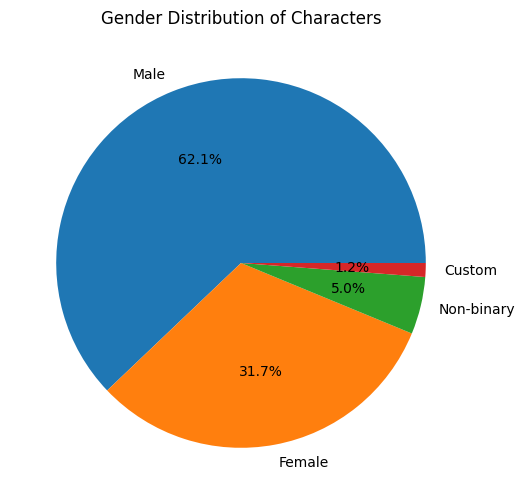

In [5]:
plt.figure(figsize=(6, 6))

df_characters_aaa["Gender"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Gender Distribution of Characters")
plt.ylabel("")
plt.show()

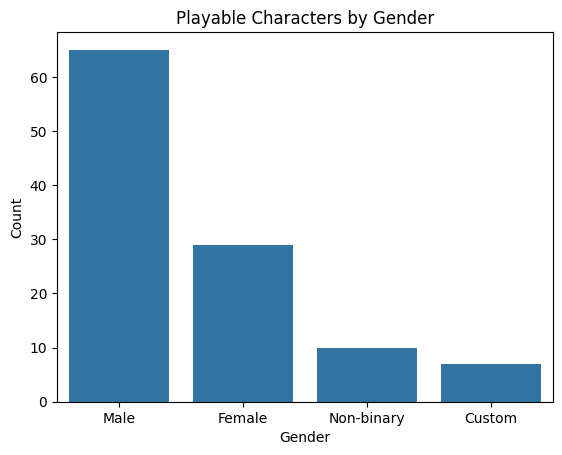

In [6]:
playable = df_characters_aaa[df_characters_aaa["Playable"] == 1]

playable_gender = playable["Gender"].value_counts().reset_index()
playable_gender.columns = ["Gender", "Count"]

sns.barplot(data=playable_gender, x="Gender", y="Count")
plt.title("Playable Characters by Gender")
plt.show()

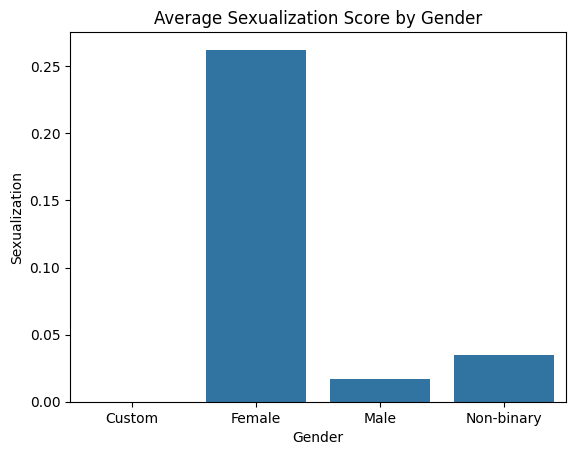

In [7]:
sexualization = (
    df_characters_aaa
    .groupby("Gender")["Sexualization"]
    .mean()
    .reset_index()
)

sns.barplot(data=sexualization, x="Gender", y="Sexualization")
plt.title("Average Sexualization Score by Gender")
plt.show()

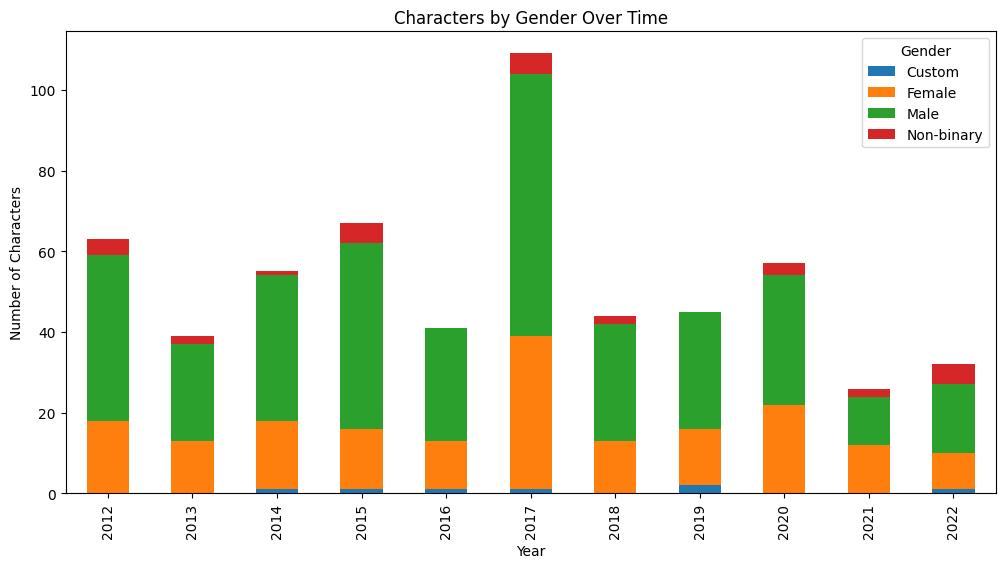

In [8]:
# Characters by gender over time
characters_year_gender_pivot = (
    df_characters_aaa
    .groupby(["year", "Gender"])
    .size()
    .reset_index(name="count")
    .pivot(index="year", columns="Gender", values="count")
    .fillna(0)
)

characters_year_gender_pivot.plot(kind="bar", stacked=True, figsize=(12, 6))

plt.title("Characters by Gender Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Characters")
plt.show()

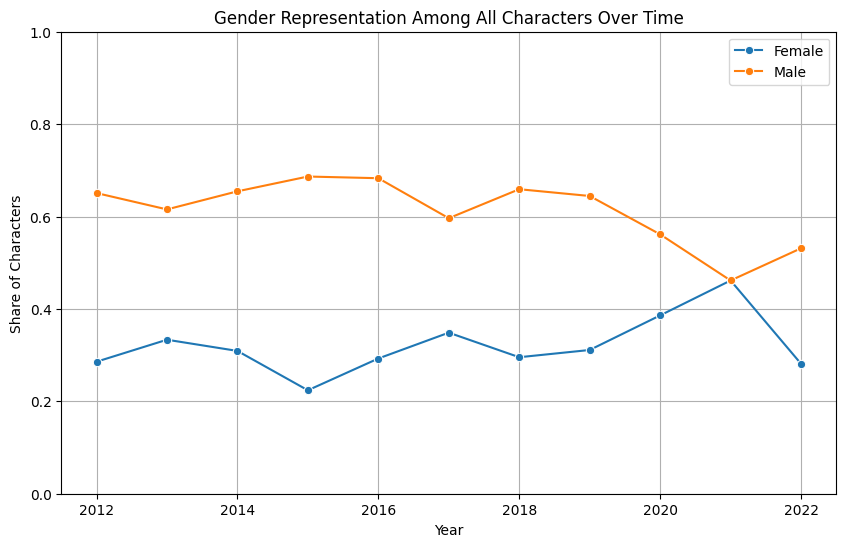

In [9]:
def gender_share_by_year(df):
    pivot = (
        df.groupby(["year", "Gender"])
        .size()
        .reset_index(name="count")
        .pivot(index="year", columns="Gender", values="count")
        .fillna(0)
    )
    pivot["total"] = pivot.sum(axis=1)
    pivot["female_share"] = pivot["Female"] / pivot["total"]
    pivot["male_share"] = pivot["Male"] / pivot["total"]
    return pivot

def plot_gender_share(pivot, title, ylabel):
    plt.figure(figsize=(10, 6))
    sns.lineplot(x=pivot.index, y=pivot["female_share"], marker="o", label="Female")
    sns.lineplot(x=pivot.index, y=pivot["male_share"], marker="o", label="Male")
    plt.title(title)
    plt.xlabel("Year")
    plt.ylabel(ylabel)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.show()

# Female share among all characters over time
gender_pivot = gender_share_by_year(df_characters_aaa)
plot_gender_share(gender_pivot, "Gender Representation Among All Characters Over Time", "Share of Characters")

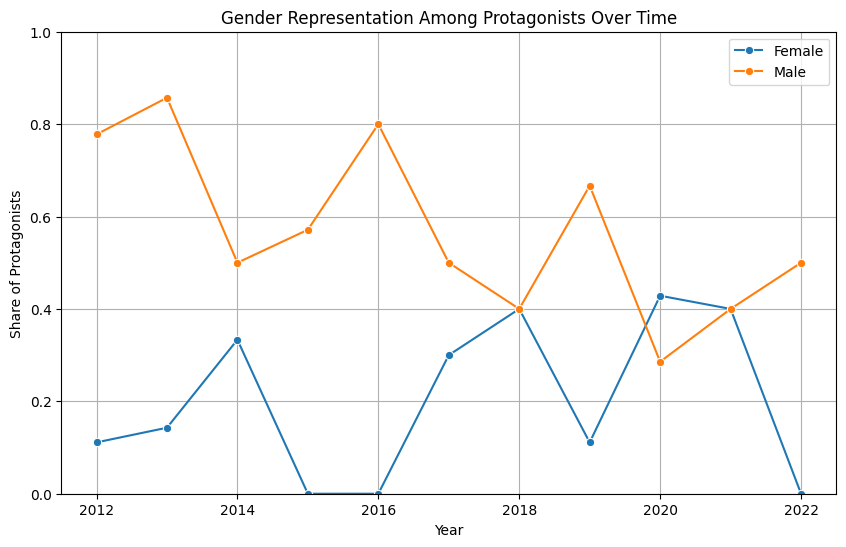

In [10]:
# Gender representation among protagonists (Relevance == "PA") over time
prot_pivot = gender_share_by_year(df_characters_aaa[df_characters_aaa["Relevance"] == "PA"])
plot_gender_share(prot_pivot, "Gender Representation Among Protagonists Over Time", "Share of Protagonists")

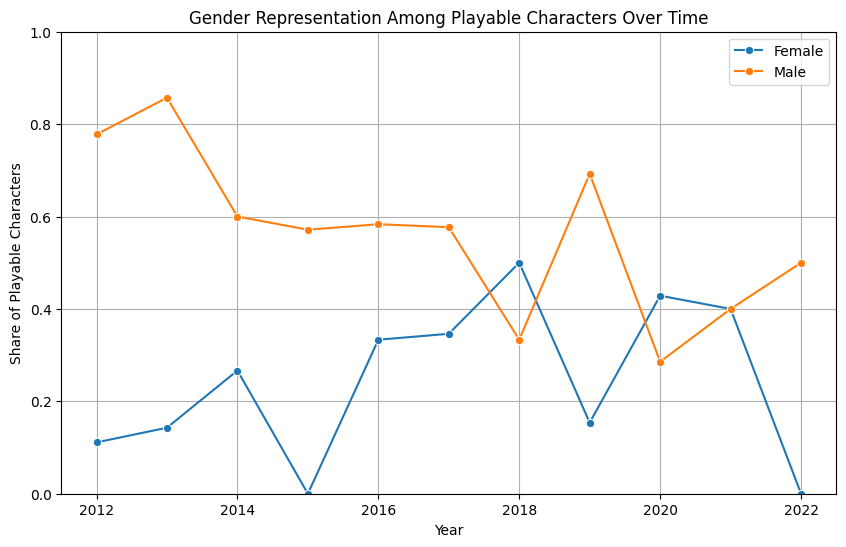

In [11]:
# Gender representation among playable characters over time
playable_pivot = gender_share_by_year(df_characters_aaa[df_characters_aaa["Playable"] == 1])
plot_gender_share(playable_pivot, "Gender Representation Among Playable Characters Over Time", "Share of Playable Characters")

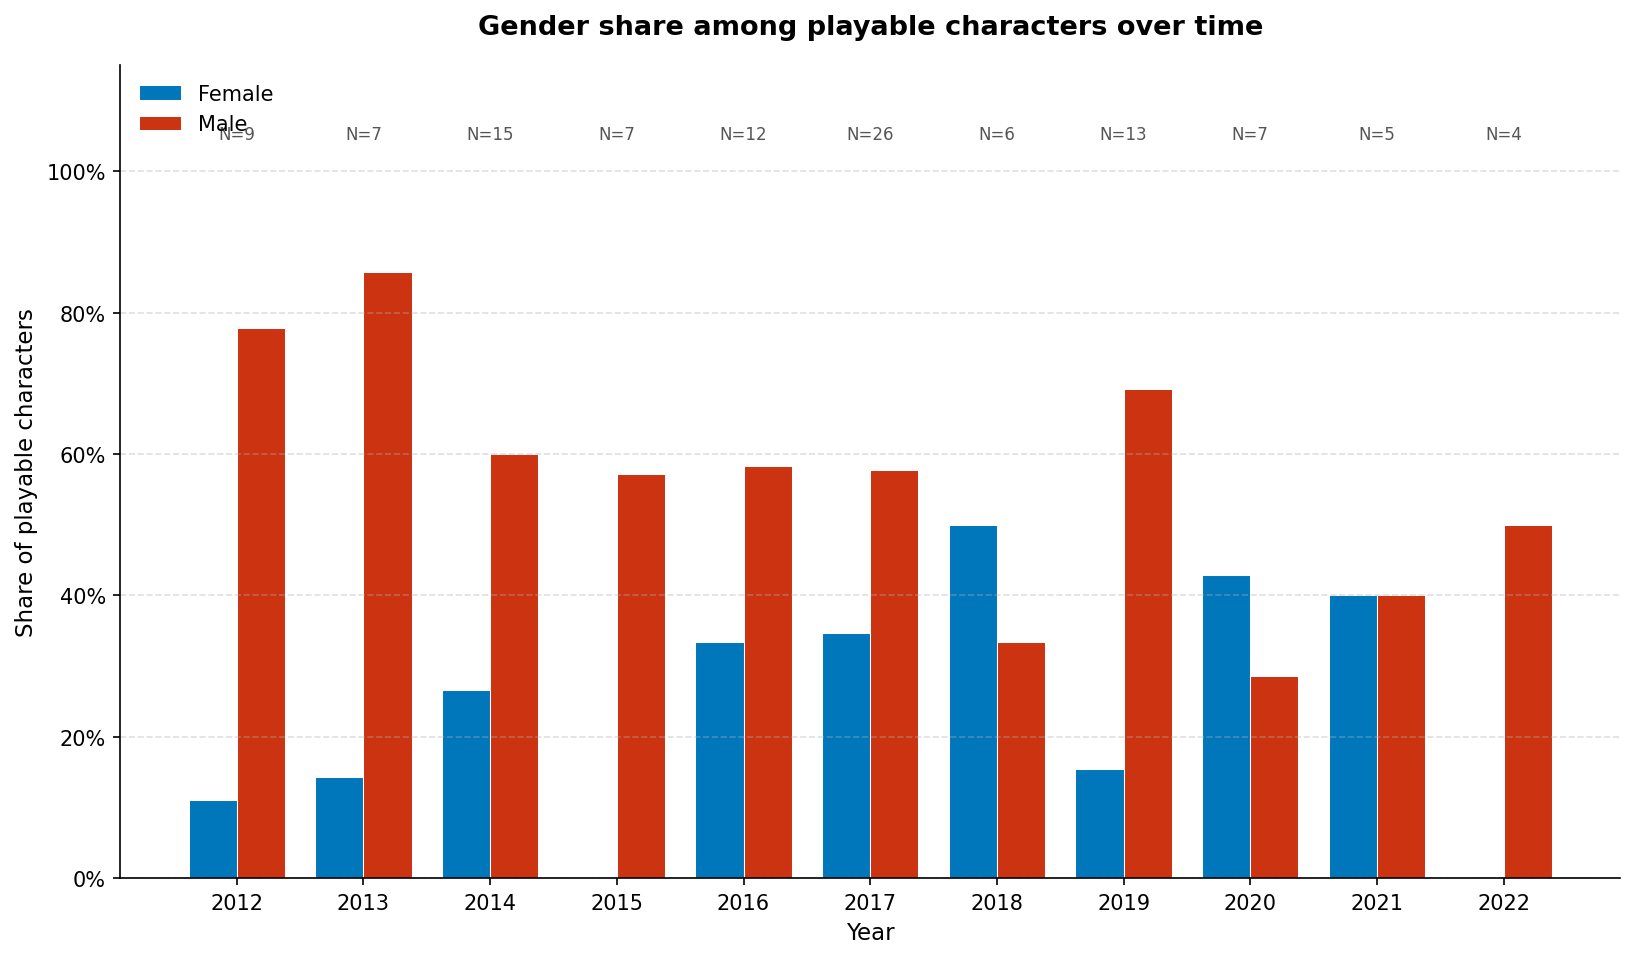

In [12]:
years = playable_pivot.index.astype(int)
female_share = playable_pivot["female_share"]
male_share = playable_pivot["male_share"]
totals = playable_pivot["total"]

x = np.arange(len(years))
width = 0.38

fig, ax = plt.subplots(figsize=(11, 6.5), dpi=150)

ax.bar(x - width/2, female_share, width, label="Female",
       color="#0077BB", edgecolor="white", linewidth=0.5)
ax.bar(x + width/2, male_share, width, label="Male",
       color="#CC3311", edgecolor="white", linewidth=0.5)

# Number of playable characters per year
for xi, n in zip(x, totals):
    ax.text(xi, 1.04, f"N={int(n)}", ha="center", va="bottom",
            fontsize=8, color="#555555")

ax.set_title("Gender share among playable characters over time",
             fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Share of playable characters", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_ylim(0, 1.15)  # extra room at the top for the "N=" labels
ax.legend(frameon=False, fontsize=10, loc="upper left")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "playable_share_by_year.png"), dpi=300, bbox_inches="tight")
plt.show()

In [13]:
print(playable_pivot[["Female", "Male", "total", "female_share", "male_share"]].round(3))

Gender  Female  Male  total  female_share  male_share
year                                                 
2012       1.0   7.0    9.0         0.111       0.778
2013       1.0   6.0    7.0         0.143       0.857
2014       4.0   9.0   15.0         0.267       0.600
2015       0.0   4.0    7.0         0.000       0.571
2016       4.0   7.0   12.0         0.333       0.583
2017       9.0  15.0   26.0         0.346       0.577
2018       3.0   2.0    6.0         0.500       0.333
2019       2.0   9.0   13.0         0.154       0.692
2020       3.0   2.0    7.0         0.429       0.286
2021       2.0   2.0    5.0         0.400       0.400
2022       0.0   2.0    4.0         0.000       0.500


The chart shows the female and male shares among playable characters per release year (shares do not add up to 100% because non-binary and custom characters are also counted in the total). Both series oscillate sharply, with no clear linear trend (r = 0.25, p = 0.46 for the playable series; see the effect-size section). The structural asymmetry, however, is consistent: the male share exceeds the female share in 8 of the 11 years between 2012 and 2022, reaching 85.7% in 2013 and 69.2% in 2019, and there are no playable female characters in 2015 and 2022. The female share exceeds the male share only in 2018 (50.0% vs. 33.3%) and 2020 (42.9% vs. 28.6%), and the two are equal in 2021 (40.0%), results that should be read with caution given the small number of playable characters per year (N between 4 and 26). The absence of a progressive trend indicates that the representation of playable female characters did not improve systematically over the period.

## 3. Distribution by game genre

In [14]:
df_chars_genre = df_characters_aaa.merge(
    df_aaa[["Game_Id", "Genre"]],
    left_on="Game",
    right_on="Game_Id",
    how="left"
)

gender_by_genre = (
    df_chars_genre
    .groupby("Genre")["Gender"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .unstack(fill_value=0)
)

gender_by_genre.sort_values("Female", ascending=False)

Gender,Custom,Female,Male,Non-binary
Genre,,,,
Adventure,0.00,38.89,51.39,9.72
RPG,4.09,35.67,56.73,3.51
Simulation,0.00,33.33,66.67,0.00
Action-adventure,0.00,28.78,66.34,4.88
Action,0.00,26.96,68.70,4.35
Interactive Story,0.00,22.22,66.67,11.11


Male characters form an absolute majority (above 50%) in all six genres, from 51.39% in Adventure to 68.70% in Action. The highest share of female characters is found in Adventure (38.89%), followed by RPG (35.67%) and Simulation (33.33%), while Interactive Story has the lowest (22.22%); among the genres with the most titles, Action has the lowest female representation (26.96%, against 28.78% in Action-adventure and 35.67% in RPG). Non-binary characters are concentrated in Interactive Story (11.11%) and Adventure (9.72%), suggesting that games with more open narratives tend to offer greater diversity of gender identities. Female underrepresentation across all genres indicates that the imbalance is not a feature of a specific genre but a transversal characteristic of the corpus.

## 4. Narrative roles, playability and romantic interest

In [15]:
# Relevance coding (Palomar, 2022):
#   PA - protagonist         -> the most important character of the game
#   DA - deuteragonist       -> second most important character of the plot
#   SK - sidekick            -> accompanies the protagonist; little relevance to the plot
#   MC - main character      -> character relevant throughout the story
#                               (the author notes that this category MAY INCLUDE ANTAGONISTS)
#   SC - secondary character -> occasional relevance to the plot
#   MA - main antagonist     -> main antagonist

relevance_by_gender = (
    pd.crosstab(
        df_characters_aaa["Gender"],
        df_characters_aaa["Relevance"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)
print("Narrative role by gender (%)")
relevance_by_gender

Narrative role by gender (%)


Relevance,DA,MA,MC,PA,SC,SK
Gender,,,,,,
Custom,0.00,0.00,0.00,100.00,0.00,0.00
Female,4.37,5.46,38.80,8.20,39.89,3.28
Male,2.79,10.31,30.92,11.98,42.34,1.67
Non-binary,0.00,13.79,10.34,31.03,27.59,17.24


The distribution of narrative roles by gender shows relevant asymmetries. Female characters hold the main character role (MC) in 38.80% of cases, more than male characters (30.92%). This reading must be qualified: the most frequent category among female characters is secondary character (SC), with 39.89%, and their share in the protagonist role (PA) is lower than the male share (8.20% vs. 11.98%). Female characters appear more often as deuteragonists (DA; 4.37% vs. 2.79%) and as sidekicks (SK; 3.28% vs. 1.67%), the latter a category of low relevance to the plot. Non-binary characters stand out for their concentration in the protagonist role (PA; 31.03%), a result to be read with caution given the small number of characters in this category (N = 29). Overall, although female characters frequently appear in narratively central positions, they rarely hold the protagonist role, and their presence in secondary and peripheral roles is still substantial.

In [16]:
playable_by_gender = (
    pd.crosstab(
        df_characters_aaa["Gender"],
        df_characters_aaa["Playable"],
        normalize="index"
    )
    .mul(100)
    .round(2)
    .rename(columns={0: "Non-playable (%)", 1: "Playable (%)"})
)
print("Playability by gender")
playable_by_gender

Playability by gender


Playable,Non-playable (%),Playable (%)
Gender,,
Custom,0.00,100.00
Female,84.15,15.85
Male,81.89,18.11
Non-binary,65.52,34.48


Most characters in the corpus, regardless of gender, are not controlled by the player. Male characters have a playability rate of 18.11%, close to the female rate (15.85%), a difference of about 2.3 percentage points. Non-binary characters have the highest playability rate in the corpus (34.48%), a result influenced by the small number of characters in this category and by their concentration in titles with a customizable protagonist. Although the female-male difference is modest in absolute terms, it becomes relevant when combined with the protagonism data: female characters often appear as main characters but are less frequently playable than male characters, suggesting that part of this centrality occurs in passive or non-controllable narrative roles, which limits the player's effective agency with female characters.

In [17]:
romantic_by_gender = (
    pd.crosstab(
        df_characters_aaa["Gender"],
        df_characters_aaa["Romantic_Interest"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)
print("Romantic interest by gender (%)")
romantic_by_gender

Romantic interest by gender (%)


Romantic_Interest,No,Opt,Yes
Gender,,,
Custom,100.00,0.00,0.00
Female,85.25,7.10,7.65
Male,96.94,2.23,0.84
Non-binary,100.00,0.00,0.00


The romantic interest role is strongly gendered. Female characters are coded as declared romantic interests (Yes) in 7.65% of cases, against 0.84% of male characters, a difference of about nine times. Adding the Opt category (optional romantic interest, present in games with relationship systems), the female share reaches 14.75%, against 3.06% for male characters (2.23% of male characters receive the optional code), a difference of about five times. Almost all male characters (96.94%) have no romantic function, whereas about one in seven female characters carries some romantic dimension in their narrative characterization. The romantic interest function is thus attributed predominantly to female characters and rarely used as a defining trait of male characters.

## 5. Sexualization - descriptive

In [18]:
sex_dist = (
    pd.crosstab(
        df_characters_aaa["Gender"],
        df_characters_aaa["Sexualization"],
        normalize="index"
    )
    .mul(100)
    .round(2)
    .add_prefix("Index = ")
)
print("Distribution of sexualization index values by gender (%)")
sex_dist

Distribution of sexualization index values by gender (%)


Sexualization,Index = 0,Index = 1,Index = 2,Index = 3
Gender,,,,
Custom,100.00,0.00,0.00,0.00
Female,84.15,7.10,7.10,1.64
Male,98.61,1.11,0.28,0.00
Non-binary,96.55,3.45,0.00,0.00


In [19]:
# Mean index (0 to 4) by gender x narrative relevance
sex_relevance = (
    df_characters_aaa
    .groupby(["Gender", "Relevance"])["Sexualization"]
    .mean()
    .round(2)
    .unstack("Relevance")
)

print("=== Mean sexualization index by gender x narrative relevance ===")
print("(Scale: 0 to 4, sum of four binary dimensions)")
sex_relevance

=== Mean sexualization index by gender x narrative relevance ===
(Scale: 0 to 4, sum of four binary dimensions)


Relevance,DA,MA,MC,PA,SC,SK
Gender,,,,,,
Custom,NaN,NaN,NaN,0.00,NaN,NaN
Female,0.88,0.0,0.25,0.20,0.27,0.0
Male,0.10,0.0,0.01,0.05,0.01,0.0
Non-binary,NaN,0.0,0.00,0.11,0.00,0.0


In [20]:
sex_age = (
    df_characters_aaa
    .groupby(["Gender", "Age_range"])["Sexualization"]
    .mean()
    .round(2)
    .unstack("Age_range")
)

age_order = ["Infant", "Child", "Teenager", "Young adult", "Adult", "Elderly"]
sex_age = sex_age.reindex(columns=[c for c in age_order if c in sex_age.columns])
sex_age

Age_range,Infant,Child,Teenager,Young adult,Adult,Elderly
Gender,,,,,,
Custom,NaN,0.00,0.00,NaN,0.00,NaN
Female,0.0,0.11,0.17,0.43,0.25,0.17
Male,0.0,0.08,0.00,0.00,0.02,0.05
Non-binary,NaN,0.00,0.00,NaN,0.00,NaN


The mean sexualization index by age range is practically zero for male characters in every range (from 0.00 to 0.08), while female characters have higher scores from adolescence onward. Female sexualization peaks among young adults (0.43), followed by adults (0.25). Teenage female characters also score higher than their male counterparts (0.17 vs. 0.00), a result that deserves attention. The elderly range has a non-zero score for female characters (0.17), against 0.05 for elderly male characters.

## 6. Hypothesis tests (H1-H4, numbered as in the paper)

### H1 - Proportion of games with a playable female protagonist < 50%

In [21]:
# ==============================================================
# H1 - The proportion of critically acclaimed games with a playable female
#      protagonist is statistically below 50%
#
# Game-level variable: has_female_protagonist
#   1 -> the game has at least one female character with
#        Relevance == "PA" (protagonist) and Playable == 1
#   0 -> otherwise
#
# Test: one-sided exact binomial test (observed proportion < 0.50)
#   (complementary: z-test with standard error under H0, prop_var=0.5)
# Significance level: alpha = 0.05
# ==============================================================

from scipy.stats import binomtest

# Game-level binary variable (playable characters only)
playable_chars = df_characters_aaa[df_characters_aaa["Playable"] == 1]

games_with_female_protagonist = (
    playable_chars[playable_chars["Relevance"] == "PA"]
    .groupby("Game")["Gender"]
    .apply(lambda g: int("Female" in g.values))
    .reset_index()
    .rename(columns={"Gender": "has_female_protagonist"})
)

# Make sure every game of the sample is represented
all_games = pd.DataFrame({"Game": df_aaa["Game_Id"].unique()})
games_h1 = all_games.merge(games_with_female_protagonist, on="Game", how="left")
games_h1["has_female_protagonist"] = games_h1["has_female_protagonist"].fillna(0).astype(int)

n_total  = len(games_h1)
n_female = games_h1["has_female_protagonist"].sum()
prop_obs = n_female / n_total

# Primary test: one-sided exact binomial (H0: p = 0.50 | H1: p < 0.50)
p_value = binomtest(int(n_female), n_total, p=0.50, alternative="less").pvalue

# Complementary: z-test with standard error under H0 (prop_var=0.5)
stat, p_z = proportions_ztest(
    count=n_female,
    nobs=n_total,
    value=0.50,
    alternative="smaller",
    prop_var=0.50
)

print("One-sided exact binomial test\n")
print(f"  Games with a playable female protagonist : {n_female} of {n_total}")
print(f"  Observed proportion                      : {prop_obs:.2%}")
print(f"  Reference proportion (parity)            : 50.00%")
print(f"  p-value (exact binomial, one-sided)      : {p_value:.2e}")
print(f"  z under H0 (complementary)               : {stat:.4f} | p = {p_z:.2e}")
print(f"  Conclusion : {'H1 supported - proportion significantly below 50% (p < 0.05)' if p_value < 0.05 else 'H0 not rejected (p >= 0.05)'}")

One-sided exact binomial test

  Games with a playable female protagonist : 14 of 60
  Observed proportion                      : 23.33%
  Reference proportion (parity)            : 50.00%
  p-value (exact binomial, one-sided)      : 2.11e-05
  z under H0 (complementary)               : -4.1312 | p = 1.80e-05
  Conclusion : H1 supported - proportion significantly below 50% (p < 0.05)


The one-sided exact binomial test supports H1 (p = 2.11 x 10^-5; z under H0 = -4.13, p = 1.80 x 10^-5): 14 of the 60 games in the sample (23.33%) have at least one playable female protagonist, identified by the code `Relevance == "PA"` (*protagonist* in Palomar's 2022 coding), a proportion significantly below the 50% parity benchmark. The PA code is used instead of MC (*main character*) because the original coding notes that MC may include antagonists, while PA is the specific designation of the protagonist. The sensitivity analysis below shows that the H1 conclusion holds under the three possible definitions of protagonism. The 23.33% value differs from the external benchmark of 6% reported by UNESCO (2024) for the best-selling games released between 1985 and 2022, which may reflect differences in sample and coding criteria between the two studies; both findings nonetheless point in the same direction - a statistically significant underrepresentation of playable female protagonists.

In [22]:
# ==============================================================
# H1 - Sensitivity to the definition of protagonist
#
# Checks whether the H1 conclusion (share of female protagonists < 50%)
# holds under different definitions of "protagonist" in the Relevance
# variable, and not only under the primary PA criterion.
# ==============================================================

print("Sensitivity to the protagonist criterion (H1)\n")
for label, rels in [("PA (protagonist)", ["PA"]),
                    ("PA or MC (broad)", ["PA", "MC"]),
                    ("MC only", ["MC"])]:
    flags = (
        playable_chars[playable_chars["Relevance"].isin(rels)]
        .groupby("Game")["Gender"].apply(lambda g: int("Female" in g.values))
        .reindex(df_aaa["Game_Id"].unique()).fillna(0)
    )
    k, n = int(flags.sum()), len(flags)
    pv = binomtest(k, n, p=0.50, alternative="less").pvalue
    print(f"  {label:32s}: {k}/{n} = {k/n:.2%} | exact binomial p = {pv:.2e}")

Sensitivity to the protagonist criterion (H1)

  PA (protagonist)                : 14/60 = 23.33% | exact binomial p = 2.11e-05
  PA or MC (broad)                : 19/60 = 31.67% | exact binomial p = 3.11e-03
  MC only                         : 5/60 = 8.33% | exact binomial p = 5.19e-12


Under the three definitions tested, the observed proportion remains significantly below 50% (p < 0.01 in all cases), which indicates that the H1 conclusion does not depend on the exact boundary between the PA and MC categories. The magnitude of the effect, however, varies considerably: from 8.33% under the most restrictive criterion (MC only) to 31.67% under the broadest (PA or MC). The primary criterion for H1 (PA, 23.33%) lies in between and is the one that best matches the definition of protagonist in the original coding (Palomar, 2022).

In [23]:
# ==============================================================
# H1 - Sensitivity to the playability requirement
#
# How much of the observed proportion comes from requiring
# Playable == 1, and not only Relevance == "PA"? Also compares
# the MC criterion and the broad criterion (PA or MC) to show
# why MC and PA are not interchangeable in this sample.
# ==============================================================

def games_with_female_relevance(relevances, require_playable):
    base = df_characters_aaa[df_characters_aaa["Relevance"].isin(relevances)]
    if require_playable:
        base = base[base["Playable"] == 1]
    flags = (
        base.groupby("Game")["Gender"]
        .apply(lambda g: int("Female" in g.values))
        .reindex(df_aaa["Game_Id"].unique())
        .fillna(0)
    )
    return int(flags.sum())

n_pa_strict = games_with_female_relevance(["PA"], require_playable=True)
n_pa_any    = games_with_female_relevance(["PA"], require_playable=False)
n_mc_strict = games_with_female_relevance(["MC"], require_playable=True)
n_mc_any    = games_with_female_relevance(["MC"], require_playable=False)
n_central_strict = games_with_female_relevance(["PA", "MC"], require_playable=True)
n_central_any    = games_with_female_relevance(["PA", "MC"], require_playable=False)

print("=== H1 - Sensitivity to the playability requirement ===\n")
print(f"PA + Playable==1 (H1 criterion)        : {n_pa_strict} games")
print(f"PA, any playability                    : {n_pa_any} games  (difference: {n_pa_any - n_pa_strict})")
print(f"MC + Playable==1                       : {n_mc_strict} games")
print(f"MC, any playability                    : {n_mc_any} games  (difference: {n_mc_any - n_mc_strict})")
print(f"PA or MC (broad) + Playable==1         : {n_central_strict} games")
print(f"PA or MC (broad), any playability      : {n_central_any} games  (difference: {n_central_any - n_central_strict})")

=== H1 - Sensitivity to the playability requirement ===

PA + Playable==1 (H1 criterion)        : 14 games
PA, any playability                    : 14 games  (difference: 0)
MC + Playable==1                       : 5 games
MC, any playability                    : 40 games  (difference: 35)
PA or MC (broad) + Playable==1         : 19 games
PA or MC (broad), any playability      : 44 games  (difference: 25)


For the H1 criterion (PA), requiring `Playable == 1` does not change the result: the 14 games with a female PA protagonist are all playable - a difference of 0. The picture is very different under the MC criterion: only 5 of the 40 games with a female MC character make that character playable, a difference of 35 games. This shows why MC is not a good proxy for playable protagonism: the category mixes characters central to the plot with characters the player does not control (including antagonists, as noted in the coding), while PA already carries playability as part of its operational definition. Under the broad criterion (PA or MC, i.e., any female character in a protagonist or central narrative position), 44 of the 60 games have at least one such character, but only 19 of them also make her playable - a gap of 25 games between narrative presence and effective control.

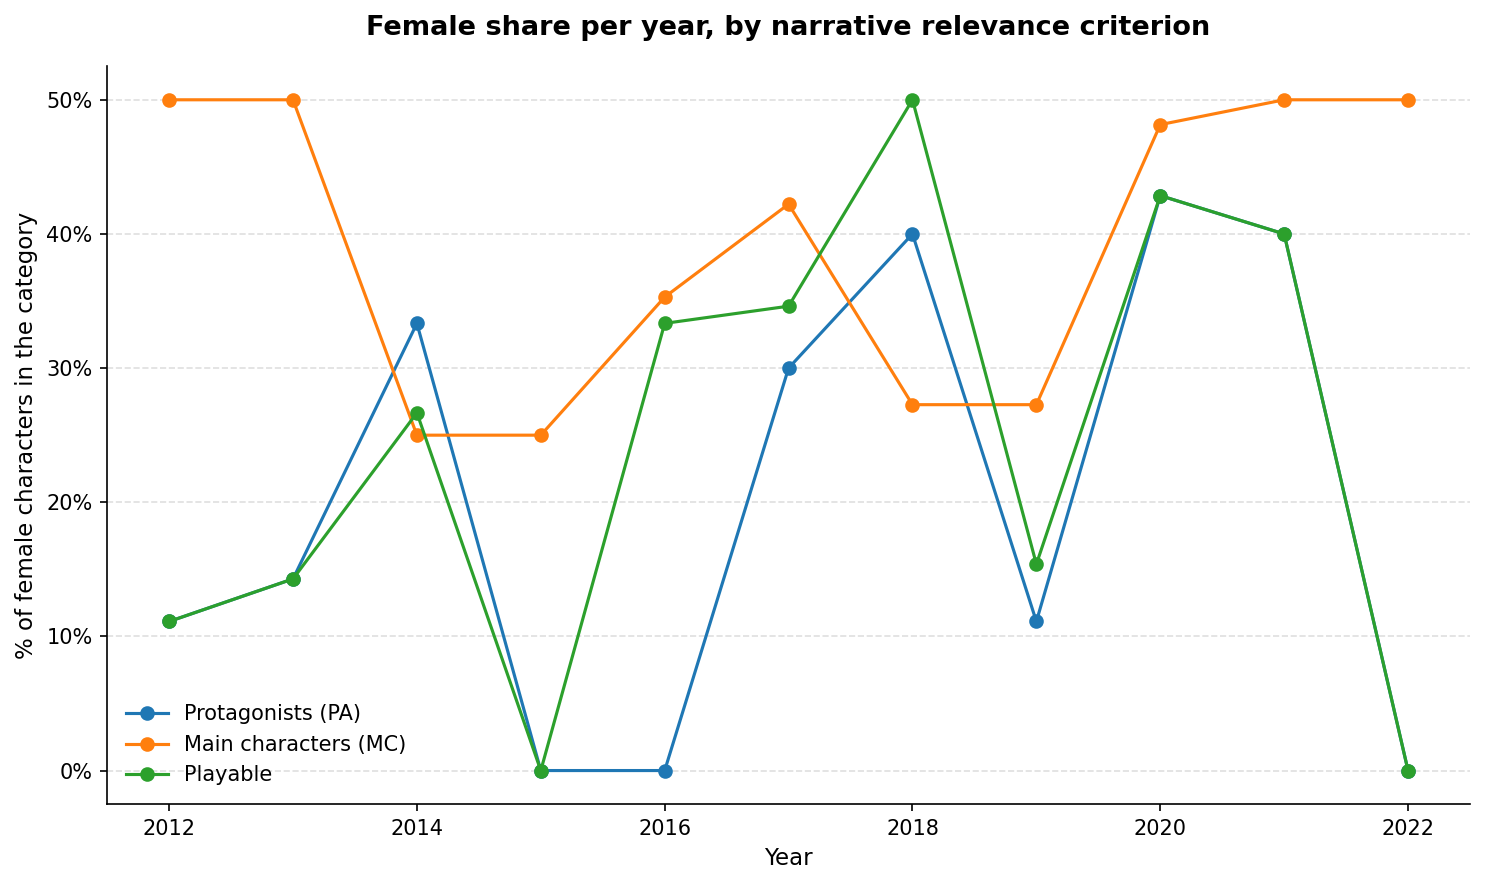

,Protagonists (PA),Main characters (MC),Playable
year,,,
2012,11.11,50.00,11.11
2013,14.29,50.00,14.29
2014,33.33,25.00,26.67
2015,0.00,25.00,0.00
2016,0.00,35.29,33.33
2017,30.00,42.22,34.62
2018,40.00,27.27,50.00
2019,11.11,27.27,15.38
2020,42.86,48.15,42.86


In [24]:
# ==============================================================
# H1 - Female share per year under three relevance criteria
# ==============================================================

series = {}
for label, mask in [
    ("Protagonists (PA)", df_characters_aaa["Relevance"] == "PA"),
    ("Main characters (MC)", df_characters_aaa["Relevance"] == "MC"),
    ("Playable", df_characters_aaa["Playable"] == 1),
]:
    sub = df_characters_aaa[mask]
    series[label] = sub.groupby("year")["Gender"].apply(lambda g: (g == "Female").mean() * 100)

female_share_by_year = pd.DataFrame(series)

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)
female_share_by_year.plot(marker="o", ax=ax)

ax.set_title("Female share per year, by narrative relevance criterion",
             fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("% of female characters in the category", fontsize=11)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.legend(frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "female_share_by_role_year.png"), dpi=300, bbox_inches="tight")
plt.show()

female_share_by_year.round(2)

### Complementary test - non-sexualized female protagonists in the H3 sub-periods (2012-2014 and 2015-2022)

Complementary test, outside the formal hypotheses (H1-H4): checks whether games with at least one playable female protagonist (PA) with no sexualization (`Sexualization == 0`) are proportionally more frequent in 2015-2022 than in 2012-2014, the same sub-periods used in H3. It is repeated under the broad criterion (PA or MC) to check whether the conclusion depends on the definition used.

In [25]:
from scipy.stats import fisher_exact

pre_games  = df_aaa[df_aaa["year"] <= 2014]
post_games = df_aaa[df_aaa["year"] >= 2015]

for label, rels in [("PA (primary criterion)", ["PA"]), ("PA or MC (broad)", ["PA", "MC"])]:
    crit = (
        (df_characters_aaa["Gender"] == "Female")
        & (df_characters_aaa["Playable"] == 1)
        & (df_characters_aaa["Relevance"].isin(rels))
        & (df_characters_aaa["Sexualization"] == 0)
    )
    games_ok = set(df_characters_aaa.loc[crit, "Game"])

    a, b = pre_games["Game_Id"].isin(games_ok).sum(), len(pre_games)
    c, d = post_games["Game_Id"].isin(games_ok).sum(), len(post_games)

    odds, p = fisher_exact([[a, b - a], [c, d - c]], alternative="less")
    p_two = fisher_exact([[a, b - a], [c, d - c]], alternative="two-sided")[1]
    print(f"{label:24s}: 2012-2014 {a}/{b} = {a/b:.2%} | 2015-2022 {c}/{d} = {c/d:.2%} | Fisher p = {p:.3f} (one-sided) | {p_two:.3f} (two-sided)")

PA (primary criterion)  : 2012-2014 3/15 = 20.00% | 2015-2022 9/45 = 20.00% | Fisher p = 0.657 (one-sided) | 1.000 (two-sided)
PA or MC (broad)        : 2012-2014 4/15 = 26.67% | 2015-2022 13/45 = 28.89% | Fisher p = 0.575 (one-sided) | 1.000 (two-sided)


Fisher's exact test finds no evidence that games with a playable, non-sexualized female protagonist are more frequent in 2015-2022 than in 2012-2014. Under the PA criterion, the proportions are identical in the two sub-periods (3/15 = 20.00% vs. 9/45 = 20.00%; p = 0.657, one-sided; p = 1.000, two-sided). Under the broad criterion, PA or MC, the difference is minimal (4/15 = 26.67% vs. 13/45 = 28.89%; p = 0.575, one-sided; p = 1.000, two-sided). The conclusion does not depend on the definition used and is consistent with the H3 result (no significant decline in the sexualization of playable female characters): non-sexualized female protagonists exist in both sub-periods but did not become proportionally more frequent after 2015.

### H2 - Female characters are more likely to be sexualized than male characters

Three complementary tests:
1. **Mann-Whitney U** on the index (primary test)
2. **Chi-square + Cramér's V** on the binary form of the index (index > 0)
3. **Logistic regression** of the binary indicator on a female dummy (male as reference), also with cluster-robust standard errors by game

In [26]:
# Binary sexualization variable (used by the three tests)
df_characters_aaa["sexualized"] = (df_characters_aaa["Sexualization"] > 0).astype(int)

table_h2 = pd.crosstab(
    df_characters_aaa["Gender"],
    df_characters_aaa["sexualized"],
    rownames=["Gender"],
    colnames=["Sexualized"]
)
print("=== Contingency table: Gender x Sexualized ===\n")
print(table_h2)

=== Contingency table: Gender x Sexualized ===

Sexualized    0   1
Gender             
Custom        7   0
Female      154  29
Male        354   5
Non-binary   28   1


In [27]:
# --- H2.1 - Mann-Whitney U ---
# Compares the distributions of the index (0-4) between female and male characters
# Alternative: female characters have HIGHER scores than male characters

fem_scores  = df_characters_aaa[df_characters_aaa["Gender"] == "Female"]["Sexualization"]
male_scores = df_characters_aaa[df_characters_aaa["Gender"] == "Male"]["Sexualization"]

stat_mw, p_mw = stats.mannwhitneyu(fem_scores, male_scores, alternative="greater")

print("=== H2.1 - Mann-Whitney U ===\n")
print(f"  U statistic : {stat_mw:.2f}")
print(f"  p-value     : {p_mw:.2e}")
print(f"  Conclusion  : {'Significant difference (p < 0.05)' if p_mw < 0.05 else 'No evidence of a significant difference'}")

=== H2.1 - Mann-Whitney U ===

  U statistic : 37623.50
  p-value     : 2.20e-11
  Conclusion  : Significant difference (p < 0.05)


In [28]:
# --- H2.2 - Chi-square + Cramér's V ---
# H2 compares female and male characters: 2x2 table (N = 542), no continuity correction
table_h2_fm = table_h2.loc[["Female", "Male"]]
chi2, p_chi2, dof, expected = chi2_contingency(table_h2_fm, correction=False)
n = table_h2_fm.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(table_h2_fm.shape) - 1)))

def effect_label(v):
    return "negligible" if v < 0.1 else "small" if v < 0.3 else "moderate" if v < 0.5 else "strong"

print("=== H2.2 - Chi-square test of independence (female x male) ===\n")
print(f"  N           : {n}")
print(f"  Chi2        : {chi2:.4f}")
print(f"  p-value     : {p_chi2:.2e}")
print(f"  df          : {dof}")
print(f"  Cramér's V  : {cramers_v:.4f}  ({effect_label(cramers_v)} effect)")

=== H2.2 - Chi-square test of independence (female x male) ===

  N           : 542
  Chi2        : 43.0718
  p-value     : 5.28e-11
  df          : 1
  Cramér's V  : 0.2819  (small effect)


In [29]:
# --- H2.3 - Logistic regression (statsmodels, no class balancing) ---

df_log = df_characters_aaa[["Gender", "sexualized"]].dropna().copy()
df_log = df_log[df_log["Gender"].isin(["Female", "Male"])]  # binary baseline: female/male only
df_log["female"] = (df_log["Gender"] == "Female").astype(int)

X_sm = sm.add_constant(df_log[["female"]])
y    = df_log["sexualized"]

model_sm = sm.Logit(y, X_sm).fit(disp=0)

params = model_sm.params
conf   = model_sm.conf_int()
or_df  = pd.DataFrame({
    "Odds Ratio":  np.exp(params),
    "95% CI low":  np.exp(conf[0]),
    "95% CI high": np.exp(conf[1]),
    "p-value":     model_sm.pvalues
})

print("=== H2.3 - Logistic regression (Sexualized ~ Female) ===\n")
print(or_df.round(4))

=== H2.3 - Logistic regression (Sexualized ~ Female) ===

        Odds Ratio  95% CI low  95% CI high  p-value
const       0.0141      0.0058       0.0341      0.0
female     13.3325      5.0655      35.0915      0.0


In [30]:
# --- H2.3b - Robustness: standard errors clustered by game ---
# Characters are nested in games; clustering relaxes the independence assumption
df_log_c = df_characters_aaa.loc[df_log.index, ["Game"]]
model_cluster = sm.Logit(y, X_sm).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(df_log_c["Game"])[0]}
)
ci = np.exp(model_cluster.conf_int().loc["female"])
print("=== H2.3b - Logistic regression with standard errors clustered by game ===\n")
print(f"  OR      : {np.exp(model_cluster.params['female']):.2f}")
print(f"  95% CI  : [{ci.iloc[0]:.2f}, {ci.iloc[1]:.2f}]")
print(f"  p-value : {model_cluster.pvalues['female']:.2e}")

=== H2.3b - Logistic regression with standard errors clustered by game ===

  OR      : 13.33
  95% CI  : [5.08, 34.97]
  p-value : 1.40e-07


In [31]:
# --- Comparison of the three tests ---
print("=== H2 - Summary ===\n")
print(f"{'Test':<28} {'Statistic':>14} {'p-value':>12}")
print("-" * 56)
print(f"{'Mann-Whitney U':<28} {stat_mw:>14.2f} {p_mw:>12.2e}")
print(f"{'Chi-square':<28} {chi2:>14.4f} {p_chi2:>12.2e}")
print(f"{'Logistic regression (OR)':<28} {or_df.loc['female', 'Odds Ratio']:>14.2f} {or_df.loc['female', 'p-value']:>12.2e}")
print(f"\nCramér's V (effect size): {cramers_v:.4f}")

=== H2 - Summary ===

Test                              Statistic      p-value
--------------------------------------------------------
Mann-Whitney U                     37623.50     2.20e-11
Chi-square                          43.0718     5.28e-11
Logistic regression (OR)              13.33     1.56e-07

Cramér's V (effect size): 0.2819


The three tests converge: female characters are significantly more likely to be sexualized than male characters (p < 0.001 in all three).

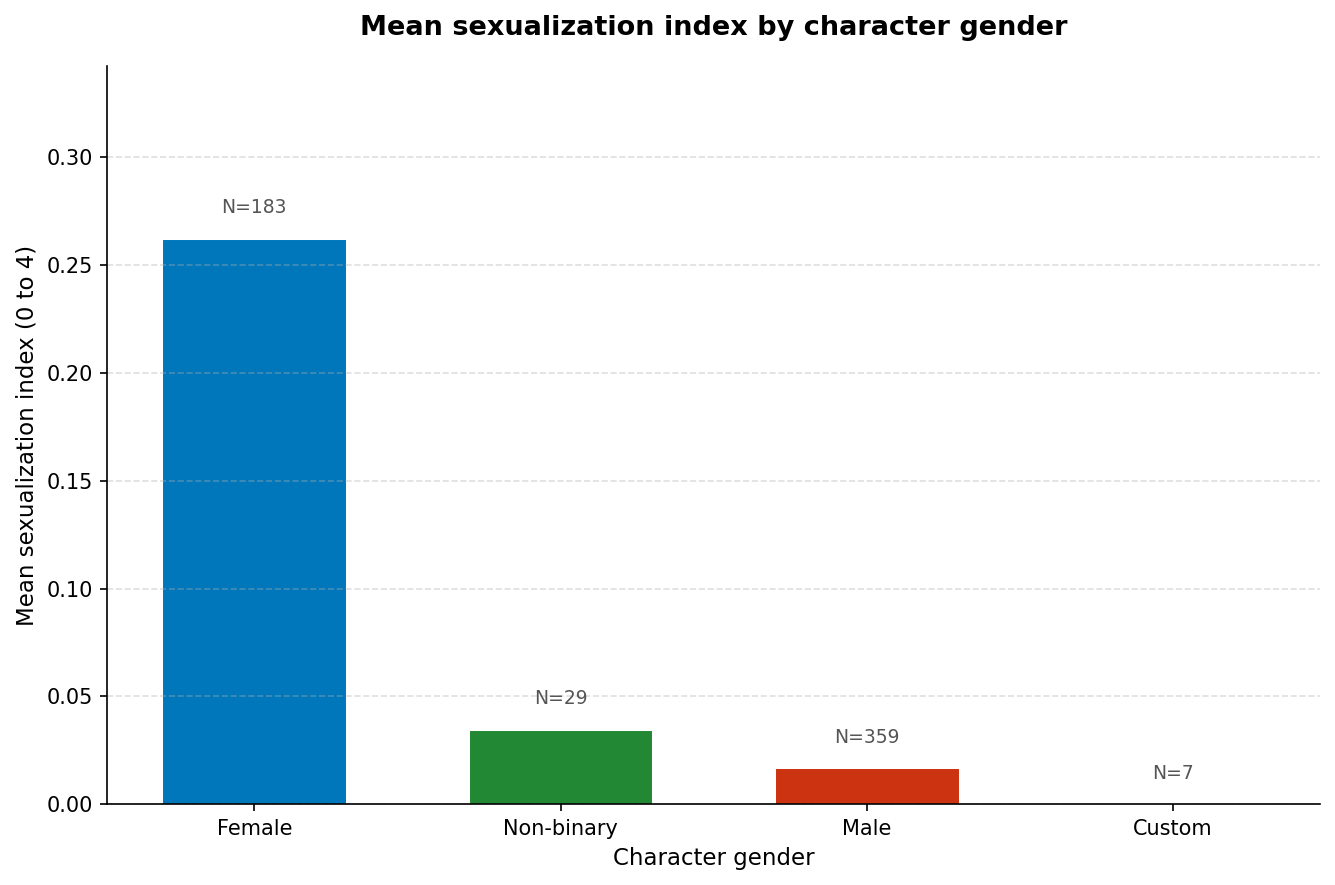

In [32]:
sexualization = (
    df_characters_aaa
    .groupby("Gender")
    .agg(Mean=("Sexualization", "mean"), N=("Sexualization", "count"))
    .reset_index()
    .sort_values("Mean", ascending=False)
)

gender_colors = {
    "Female": "#0077BB",
    "Male": "#CC3311",
    "Non-binary": "#228833",
    "Custom": "#BBBBBB",
}
colors = sexualization["Gender"].map(gender_colors)

fig, ax = plt.subplots(figsize=(9, 6), dpi=150)

ax.bar(
    sexualization["Gender"], sexualization["Mean"],
    width=0.6, color=colors, edgecolor="white", linewidth=0.5
)

for i, (mean, n) in enumerate(zip(sexualization["Mean"], sexualization["N"])):
    ax.text(i, mean + 0.01, f"N={int(n)}", ha="center", va="bottom",
            fontsize=9, color="#555555")

ax.set_title("Mean sexualization index by character gender",
             fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Character gender", fontsize=11)
ax.set_ylabel("Mean sexualization index (0 to 4)", fontsize=11)
ax.set_ylim(0, sexualization["Mean"].max() + 0.08)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sexualization_by_gender.png"), dpi=300, bbox_inches="tight")
plt.show()

### H3 - The mean sexualization of playable female characters decreased over time

First the full yearly panel (proportions per year, three charts), then the formal tests (Pearson + Welch).

,Year,Total,Female,Female sex.,Total sex.,% Female/Total,% Female sex./Female,% Female sex./Total
0,2012,63,18,4,5,28.6%,22.2%,6.3%
1,2013,39,13,4,6,33.3%,30.8%,10.3%
2,2014,55,17,3,3,30.9%,17.6%,5.5%
3,2015,67,15,5,6,22.4%,33.3%,7.5%
4,2016,41,12,2,2,29.3%,16.7%,4.9%
5,2017,109,38,8,9,34.9%,21.1%,7.3%
6,2018,44,13,0,0,29.5%,0.0%,0.0%
7,2019,45,14,0,1,31.1%,0.0%,0.0%
8,2020,57,22,1,1,38.6%,4.5%,1.8%
9,2021,26,12,0,0,46.2%,0.0%,0.0%


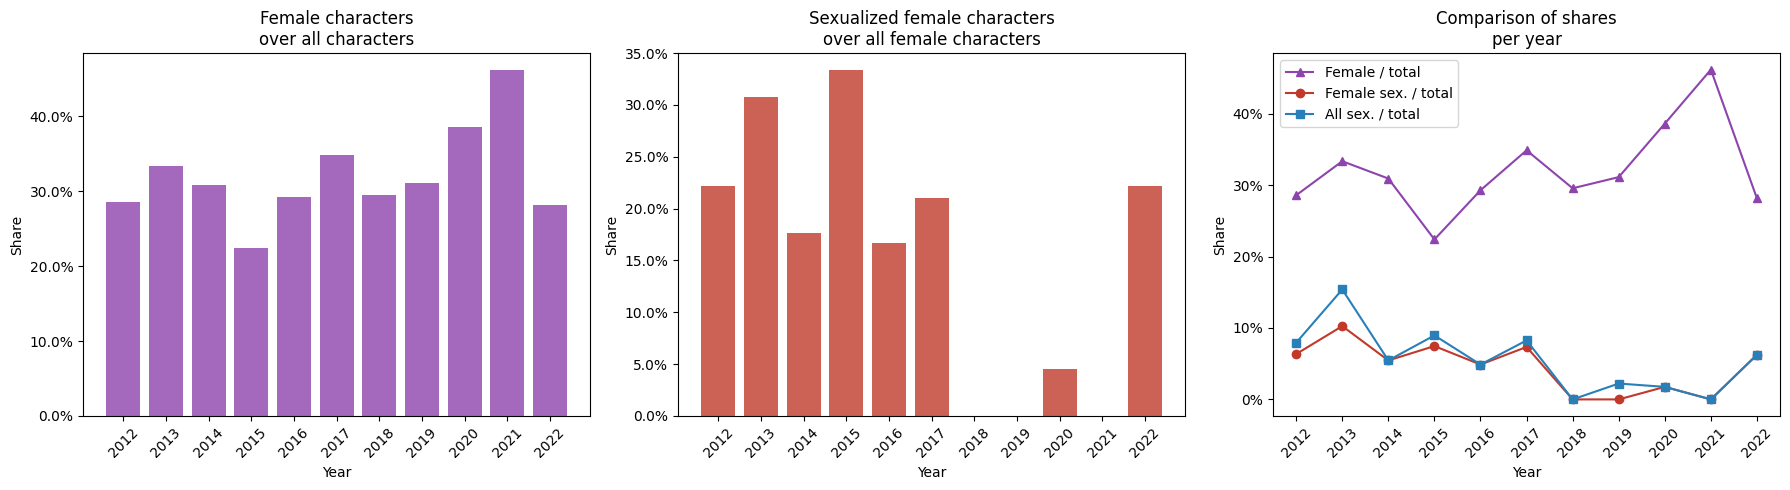

In [33]:
# TIME ANALYSIS - share of sexualized characters per year
df_temporal = df_characters_aaa.copy()
df_temporal["female"] = df_temporal["Gender"] == "Female"
df_temporal["is_sexualized"] = df_temporal["Sexualization"] > 0
df_temporal["female_sexualized"] = df_temporal["female"] & df_temporal["is_sexualized"]

by_year = df_temporal.groupby("year").agg(
    total_characters  = ("Id", "count"),
    female_total      = ("female", "sum"),
    female_sexualized = ("female_sexualized", "sum"),
    total_sexualized  = ("is_sexualized", "sum"),
).reset_index()

by_year["female_over_total"]            = by_year["female_total"]      / by_year["total_characters"]
by_year["female_sex_over_female"]       = by_year["female_sexualized"] / by_year["female_total"]
by_year["female_sex_over_total"]        = by_year["female_sexualized"] / by_year["total_characters"]
by_year["total_sex_over_total"]         = by_year["total_sexualized"]  / by_year["total_characters"]

display(by_year[[
    "year", "total_characters", "female_total",
    "female_sexualized", "total_sexualized",
    "female_over_total", "female_sex_over_female", "female_sex_over_total"
]].rename(columns={
    "year":                   "Year",
    "total_characters":       "Total",
    "female_total":           "Female",
    "female_sexualized":      "Female sex.",
    "total_sexualized":       "Total sex.",
    "female_over_total":      "% Female/Total",
    "female_sex_over_female": "% Female sex./Female",
    "female_sex_over_total":  "% Female sex./Total",
}).style.format({
    "% Female/Total":       "{:.1%}",
    "% Female sex./Female": "{:.1%}",
    "% Female sex./Total":  "{:.1%}",
}).set_properties(**{"text-align": "center"})
  .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].bar(by_year["year"], by_year["female_over_total"], color="#8e44ad", alpha=0.8)
axes[0].set_title("Female characters\nover all characters")

axes[1].bar(by_year["year"], by_year["female_sex_over_female"], color="#c0392b", alpha=0.8)
axes[1].set_title("Sexualized female characters\nover all female characters")

axes[2].plot(by_year["year"], by_year["female_over_total"],     marker="^", color="#8e44ad", label="Female / total")
axes[2].plot(by_year["year"], by_year["female_sex_over_total"], marker="o", color="#c0392b", label="Female sex. / total")
axes[2].plot(by_year["year"], by_year["total_sex_over_total"],  marker="s", color="#2980b9", label="All sex. / total")
axes[2].set_title("Comparison of shares\nper year")
axes[2].legend()

for ax in axes:
    ax.set_xlabel("Year")
    ax.set_ylabel("Share")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xticks(by_year["year"])
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [34]:
# H3 - The mean sexualization of playable female characters
#      decreased significantly over 2012-2022
#
# Tests:
#   H3a - Pearson correlation: Total index x release year
#   H3b - Welch's t-test: mean sexualization 2012-2014 vs. 2015-2022

df_sex_year = df_sex_full.merge(
    df_aaa[["Game_Id", "year"]].drop_duplicates("Game_Id"),
    left_on="Game",
    right_on="Game_Id",
    how="left"
)

# Filter: female, playable, within the period, with Total available
fem_play_h3 = df_sex_year[
    (df_sex_year["Gender"] == "Female") &
    (df_sex_year["Playable"] == 1) &
    (df_sex_year["year"].between(2010, 2022)) &
    (df_sex_year["Total"].notna())
].copy()

print(f"H3 base: {len(fem_play_h3)} playable female characters with complete data\n")

print("=== Mean sexualization per year (playable female characters) ===\n")
h3_by_year = (
    fem_play_h3.groupby("year")["Total"]
    .agg(Mean="mean", N="count")
    .round(4)
)
print(h3_by_year.to_string())

# --- H3a. Pearson correlation: Total x year ---
r_h3, p_pearson = stats.pearsonr(fem_play_h3["year"], fem_play_h3["Total"])

print("\n=== H3a - Pearson correlation: sexualization x year ===\n")
print(f"  r           : {r_h3:.4f}")
print(f"  p-value     : {p_pearson:.4f}")
print(f"  Direction   : {'Decreasing' if r_h3 < 0 else 'Increasing' if r_h3 > 0 else 'None'}")
print(f"  Conclusion  : {'Significant time trend (p < 0.05)' if p_pearson < 0.05 else 'No significant time trend (p >= 0.05)'}")

# --- H3b. Welch's t-test: 2012-2014 vs. 2015-2022 ---
pre  = fem_play_h3[fem_play_h3["year"] <= 2014]["Total"]
post = fem_play_h3[fem_play_h3["year"] >= 2015]["Total"]

t_stat, p_ttest = stats.ttest_ind(pre, post, equal_var=False)

print("\n=== H3b - Welch's t-test: 2012-2014 vs. 2015-2022 ===\n")
print(f"  Mean 2012-2014 : {pre.mean():.4f}  (N = {len(pre)})")
print(f"  Mean 2015-2022 : {post.mean():.4f}  (N = {len(post)})")
print(f"  Difference     : {post.mean() - pre.mean():.4f}")
print(f"  t statistic    : {t_stat:.4f}")
print(f"  p-value        : {p_ttest:.4f}")
print(f"  Conclusion     : {'Significant difference between sub-periods (p < 0.05)' if p_ttest < 0.05 else 'No significant difference between sub-periods (p >= 0.05)'}")

# --- Mean of each dimension by sub-period ---
print("\n=== Mean of each sexualization dimension by sub-period ===\n")
dims = ["Sexualized_clothing", "Trophy", "Damsel in Distress", "Sexualized Cutscenes"]

fem_play_h3["subperiod"] = fem_play_h3["year"].apply(
    lambda y: "2012-2014" if y <= 2014 else "2015-2022"
)

dim_subperiod = (
    fem_play_h3.groupby("subperiod")[dims]
    .mean()
    .round(4)
    .T
)
dim_subperiod.columns.name = None
print(dim_subperiod.to_string())

H3 base: 29 playable female characters with complete data

=== Mean sexualization per year (playable female characters) ===

        Mean  N
year           
2012  0.0000  1
2013  0.0000  1
2014  0.5000  4
2016  0.5000  4
2017  0.4444  9
2018  0.0000  3
2019  0.0000  2
2020  0.0000  3
2021  0.0000  2

=== H3a - Pearson correlation: sexualization x year ===

  r           : -0.1831
  p-value     : 0.3418
  Direction   : Decreasing
  Conclusion  : No significant time trend (p >= 0.05)

=== H3b - Welch's t-test: 2012-2014 vs. 2015-2022 ===

  Mean 2012-2014 : 0.3333  (N = 6)
  Mean 2015-2022 : 0.2609  (N = 23)
  Difference     : -0.0725
  t statistic    : 0.2027
  p-value        : 0.8455
  Conclusion     : No significant difference between sub-periods (p >= 0.05)

=== Mean of each sexualization dimension by sub-period ===

                      2012-2014  2015-2022
Sexualized_clothing      0.1667     0.1739
Trophy                   0.0000     0.0000
Damsel in Distress       0.0000     0.00

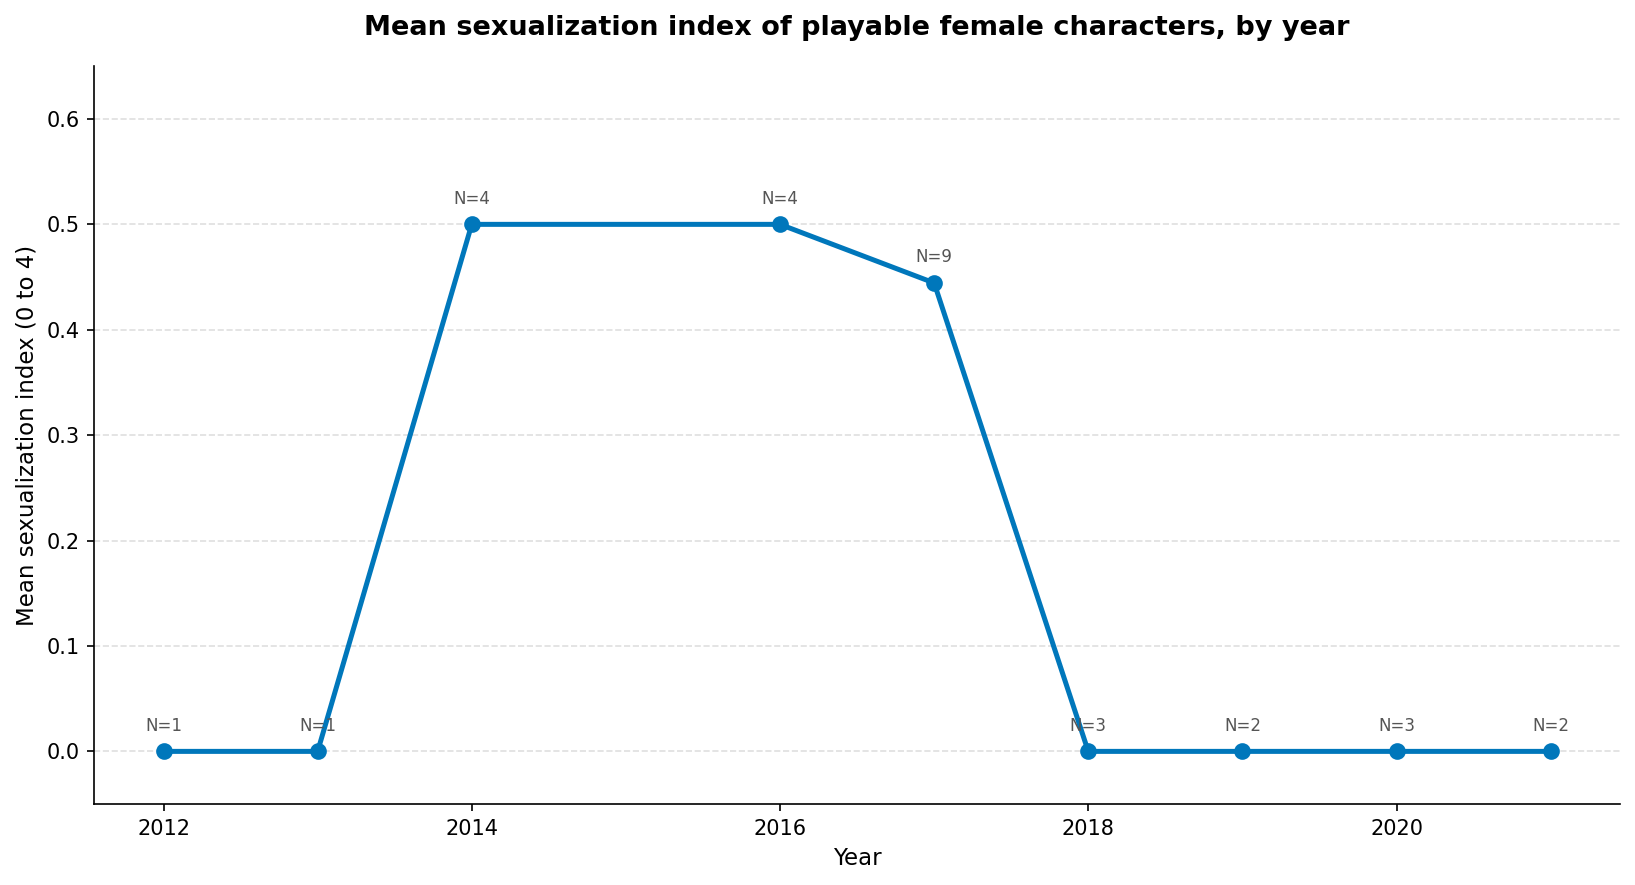

In [35]:
fig, ax = plt.subplots(figsize=(11, 6), dpi=150)

ax.plot(
    h3_by_year.index, h3_by_year["Mean"],
    marker="o", markersize=7, linewidth=2.4,
    color="#0077BB"
)

for year, row in h3_by_year.iterrows():
    ax.annotate(
        f"N={int(row['N'])}",
        (year, row["Mean"]),
        textcoords="offset points", xytext=(0, 10),
        ha="center", fontsize=8, color="#555555"
    )

ax.set_title("Mean sexualization index of playable female characters, by year",
             fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Mean sexualization index (0 to 4)", fontsize=11)
ax.set_ylim(-0.05, h3_by_year["Mean"].max() + 0.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sexualization_by_year.png"), dpi=300, bbox_inches="tight")
plt.show()

In [36]:
# H3 - Share of playable female characters with no sexualization (index = 0)
zero = fem_play_h3["Total"] == 0
print(f"Index = 0: {zero.sum()} of {len(fem_play_h3)} ({zero.mean():.2%})")
for label, mask in [("2012-2014", fem_play_h3["year"] <= 2014), ("2015-2022", fem_play_h3["year"] >= 2015)]:
    print(f"  {label}: {(fem_play_h3.loc[mask, 'Total'] == 0).sum()} of {mask.sum()}")

Index = 0: 24 of 29 (82.76%)
  2012-2014: 5 of 6
  2015-2022: 19 of 23


### Complement to H3 - sexualization over time, all female characters

H3 tests only **playable** female characters (N = 29), a small base that limits statistical power. As an exploratory complement, outside the formal hypotheses, the same analysis (Pearson + Welch, same sub-periods 2012-2014 vs. 2015-2022) is repeated on **all** female characters in the corpus, playable and non-playable (N = 183), to check whether the (non-significant) decline observed among playable characters also appears, with more statistical power, in the broader population.

In [37]:
fem_all_h3 = df_sex_year[
    (df_sex_year["Gender"] == "Female")
    & (df_sex_year["year"].between(2010, 2022))
    & (df_sex_year["Total"].notna())
].copy()

print(f"Base: {len(fem_all_h3)} female characters (playable and non-playable) with complete data\n")

print("=== Mean sexualization per year (all female characters) ===\n")
all_by_year = (
    fem_all_h3.groupby("year")["Total"]
    .agg(Mean="mean", N="count")
    .round(4)
)
print(all_by_year.to_string())

r_all, p_pearson_all = stats.pearsonr(fem_all_h3["year"], fem_all_h3["Total"])
print("\n=== Pearson correlation: sexualization x year (all female characters) ===\n")
print(f"  r       : {r_all:.4f}")
print(f"  p-value : {p_pearson_all:.6f}")

pre_all  = fem_all_h3[fem_all_h3["year"] <= 2014]["Total"]
post_all = fem_all_h3[fem_all_h3["year"] >= 2015]["Total"]
t_all, p_ttest_all = stats.ttest_ind(pre_all, post_all, equal_var=False)

print("\n=== Welch's t-test: 2012-2014 vs. 2015-2022 (all female characters) ===\n")
print(f"  Mean 2012-2014 : {pre_all.mean():.4f}  (N = {len(pre_all)})")
print(f"  Mean 2015-2022 : {post_all.mean():.4f}  (N = {len(post_all)})")
print(f"  t statistic    : {t_all:.4f}")
print(f"  p-value        : {p_ttest_all:.6f}")

Base: 183 female characters (playable and non-playable) with complete data

=== Mean sexualization per year (all female characters) ===

        Mean   N
year            
2012  0.3889  18
2013  0.6154  13
2014  0.2941  17
2015  0.6667  15
2016  0.2500  12
2017  0.2895  38
2018  0.0000  13
2019  0.0000  14
2020  0.0455  22
2021  0.0000  12
2022  0.3333   9

=== Pearson correlation: sexualization x year (all female characters) ===

  r       : -0.2211
  p-value : 0.002634

=== Welch's t-test: 2012-2014 vs. 2015-2022 (all female characters) ===

  Mean 2012-2014 : 0.4167  (N = 48)
  Mean 2015-2022 : 0.2074  (N = 135)
  t statistic    : 1.5536
  p-value        : 0.125416


When the base is extended from playable female characters (N = 29, used in H3) to all female characters in the corpus (N = 183), the correlation between sexualization and release year becomes negative and significant (r = -0.2211; p = 0.0026), but the comparison of sub-periods does not: the mean falls from 0.42 in 2012-2014 (N = 48) to 0.21 in 2015-2022 (N = 135), a difference that is not significant in Welch's t-test (t = 1.55; p = 0.125). The decline therefore appears as a gradual trend over the years rather than a break in 2015: yearly means oscillate until 2017 and stay close to zero in 2018-2021, with a single higher value in 2022 (0.33; N = 9). This does not contradict the rejection of H3 but qualifies it: there is an indication of decline in the broader population of female characters, while the playable subset, on which H3 is formally tested, is too small to capture it with statistical confidence.

### H4 - The sexualization of female characters differs across game genres

In [38]:
# Bases for H4: need Genre (of the game) + Playable + Total (sexualization index)
fem_play_h4 = df_chars_genre[
    (df_chars_genre["Gender"] == "Female") &
    (df_chars_genre["Playable"] == 1) &
    (df_chars_genre["Total"].notna())
].copy()

fem_all_h4 = df_chars_genre[
    (df_chars_genre["Gender"] == "Female") &
    (df_chars_genre["Total"].notna())
].copy()

print(f"Base 1 (playable): {len(fem_play_h4)} characters")
print(f"Base 2 (all)     : {len(fem_all_h4)} characters")

Base 1 (playable): 29 characters
Base 2 (all)     : 183 characters


In [39]:
from scipy.stats import kruskal, f_oneway, permutation_test

def stat_f(*groups):
    return f_oneway(*groups).statistic

def stat_h(*groups):
    return kruskal(*groups).statistic

print("=== H4 - BASE 1: PLAYABLE female characters ===\n")

desc_play = (
    fem_play_h4.groupby("Genre")["Total"]
    .agg(Mean="mean", SD="std", N="count")
    .round(4)
    .sort_values("Mean", ascending=False)
)
print(desc_play.to_string())

small_genres = desc_play[desc_play["N"] < 3].index.tolist()
if small_genres:
    print(f"\nWarning: N < 3 in {small_genres} - very limited statistical power")

# Groups with fewer than two characters are excluded
groups_b1 = [g["Total"].values for _, g in fem_play_h4.groupby("Genre") if len(g) >= 2]

f_b1, p_anova_b1 = f_oneway(*groups_b1)
print(f"\nOne-way ANOVA    : F = {f_b1:.4f} | p = {p_anova_b1:.4f}")

h_b1, p_kw_b1 = kruskal(*groups_b1)
print(f"Kruskal-Wallis   : H = {h_b1:.4f} | p = {p_kw_b1:.4f}")

res_f_b1 = permutation_test(
    groups_b1, stat_f,
    alternative="greater",
    n_resamples=9999,
    vectorized=False,
    random_state=42
)
print(f"Permutation (F)  : F = {res_f_b1.statistic:.4f} | p = {res_f_b1.pvalue:.4f}")

=== H4 - BASE 1: PLAYABLE female characters ===

                     Mean      SD   N
Genre                                
RPG                0.4286  0.7559  14
Action-adventure   0.4000  0.8944   5
Action             0.0000  0.0000   6
Adventure          0.0000  0.0000   3
Interactive Story  0.0000     NaN   1


One-way ANOVA    : F = 0.8172 | p = 0.4970
Kruskal-Wallis   : H = 2.8602 | p = 0.4137


Permutation (F)  : F = 0.8172 | p = 0.4683


=== H4 - BASE 2: ALL female characters (playable + NPC) ===

                     Mean      SD   N
Genre                                
Simulation         1.0000  0.0000   2
Interactive Story  0.5000  0.7071   2
Action             0.3871  0.7606  31
Action-adventure   0.3051  0.7713  59
RPG                0.2459  0.6233  61
Adventure          0.0000  0.0000  28

One-way ANOVA    : F = 1.7472 | p = 0.1262
Kruskal-Wallis   : H = 16.9801 | p = 0.0045


Permutation (F)  : F = 1.7472 | p = 0.1391


Permutation (H)  : H = 16.9801 | p = 0.0098

Conclusion: Kruskal-Wallis (p=0.0045) confirmed by the Monte Carlo permutation of H (p=0.0098) -
significant difference in the DISTRIBUTION of sexualization across game genres (Base 2).
ANOVA and the permutation of F do not detect a difference in MEANS (p=0.126 and p=0.139).


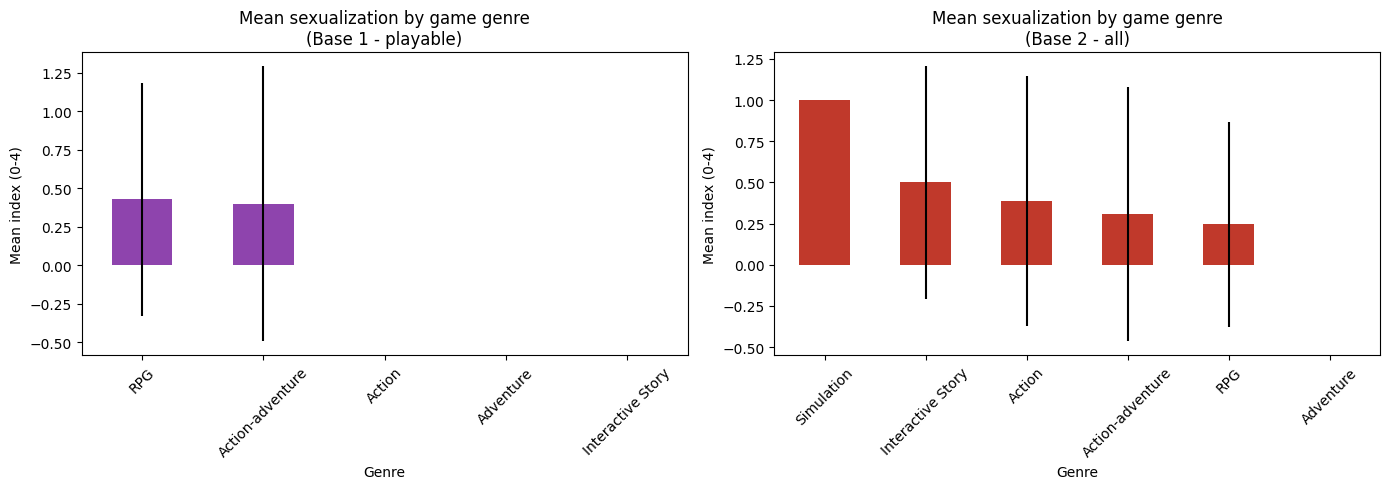

In [40]:
print("=== H4 - BASE 2: ALL female characters (playable + NPC) ===\n")

desc_all = (
    fem_all_h4.groupby("Genre")["Total"]
    .agg(Mean="mean", SD="std", N="count")
    .round(4)
    .sort_values("Mean", ascending=False)
)
print(desc_all.to_string())

groups_b2 = [g["Total"].values for _, g in fem_all_h4.groupby("Genre") if len(g) >= 2]

f_b2, p_anova_b2 = f_oneway(*groups_b2)
print(f"\nOne-way ANOVA    : F = {f_b2:.4f} | p = {p_anova_b2:.4f}")

h_b2, p_kw_b2 = kruskal(*groups_b2)
print(f"Kruskal-Wallis   : H = {h_b2:.4f} | p = {p_kw_b2:.4f}")

res_f_b2 = permutation_test(
    groups_b2, stat_f,
    alternative="greater",
    n_resamples=9999,
    vectorized=False,
    random_state=42
)
print(f"Permutation (F)  : F = {res_f_b2.statistic:.4f} | p = {res_f_b2.pvalue:.4f}")

# Permutation of H (checks Kruskal-Wallis without relying on the asymptotic approximation)
res_h_b2 = permutation_test(
    groups_b2, stat_h,
    alternative="greater",
    n_resamples=9999,
    vectorized=False,
    random_state=42
)
print(f"Permutation (H)  : H = {res_h_b2.statistic:.4f} | p = {res_h_b2.pvalue:.4f}")

alpha = 0.05
if p_kw_b2 < alpha and res_h_b2.pvalue < alpha:
    print(f"\nConclusion: Kruskal-Wallis (p={p_kw_b2:.4f}) confirmed by the Monte Carlo permutation of H (p={res_h_b2.pvalue:.4f}) -")
    print("significant difference in the DISTRIBUTION of sexualization across game genres (Base 2).")
elif p_kw_b2 < alpha:
    print(f"\nConclusion: Kruskal-Wallis significant (p={p_kw_b2:.4f}), but NOT confirmed by the Monte Carlo permutation of H (p={res_h_b2.pvalue:.4f}) -")
    print("borderline result, no robust evidence of a difference in DISTRIBUTION across game genres (Base 2).")
else:
    print(f"\nConclusion: neither Kruskal-Wallis (p={p_kw_b2:.4f}) nor the permutation of H (p={res_h_b2.pvalue:.4f}) indicate a difference in DISTRIBUTION (Base 2).")
means = "detect" if (p_anova_b2 < alpha and res_f_b2.pvalue < alpha) else "do not detect"
print(f"ANOVA and the permutation of F {means} a difference in MEANS (p={p_anova_b2:.3f} and p={res_f_b2.pvalue:.3f}).")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

desc_play["Mean"].plot(kind="bar", ax=axes[0], color="#8e44ad", yerr=desc_play["SD"])
axes[0].set_title("Mean sexualization by game genre\n(Base 1 - playable)")

desc_all["Mean"].plot(kind="bar", ax=axes[1], color="#c0392b", yerr=desc_all["SD"])
axes[1].set_title("Mean sexualization by game genre\n(Base 2 - all)")

for ax in axes:
    ax.set_ylabel("Mean index (0-4)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

The hypothesis that the sexualization of female characters differs across game genres was tested on two bases with four complementary approaches - ANOVA, Kruskal-Wallis and Monte Carlo permutation tests (B = 9,999 resamples, seed 42) on the F and H statistics - given the strong imbalance of N across genres (from 2 to 61 characters) and the ordinal nature of the sexualization index. The pre-specified primary test is the permutation of H on Base 2.

In Base 1 (playable female characters, N = 29), the three applicable tests converge: ANOVA (F = 0.82; p = 0.497), Kruskal-Wallis (H = 2.86; p = 0.414) and the permutation of F (p = 0.468) find no significant difference across game genres.

In Base 2 (all female characters, N = 183), the tests on means - ANOVA (F = 1.75; p = 0.126) and the permutation of F (p = 0.139) - find no significant difference. Kruskal-Wallis indicates a difference in the distribution of the index across genres (H = 16.98; p = 0.0045; epsilon squared = 0.09), confirmed by the permutation of H (p = 0.0098; p = 0.020 after Holm's correction). By the pre-specified criterion, H4 is therefore supported.

The robustness analysis below, conducted *post hoc*, shows, however, that the effect is small, localized and dependent on the unit of analysis. The difference is concentrated in Adventure, whose 28 female characters, from only five titles, all score zero, and in Simulation, with two characters from a single game, both sexualized; among Action, Action-adventure and RPG, which gather 151 of the 183 characters, there is no difference. When the game rather than the character is treated as the unit, whether by permuting genre labels across games or by comparing game-level means, the difference is not significant. The divergence between mean-based and rank-based tests is also explained by the data: Adventure and Simulation have zero standard deviation, while Action, Action-adventure and RPG show high internal variability (SD between 0.62 and 0.77), which dilutes the ANOVA F but does not affect the rank test.

#### H4 - Robustness to clustering by game (post hoc)

Characters are nested in games, and genres differ widely in the number of titles (Adventure has 28 female characters from only 5 games). The analyses below, conducted after the primary test, check (1) whether the Base 2 result depends on specific genres and (2) whether it holds when the game, rather than the character, is treated as the unit: permuting genre labels across games, keeping each character in its game, and Kruskal-Wallis on the mean index of the female characters of each game.

In [41]:
# ==============================================================
# H4 - Robustness to clustering by game (post hoc)
# ==============================================================

def kw_genres(df):
    groups = [g["Total"].values for _, g in df.groupby("Genre") if len(g) >= 2]
    return kruskal(*groups)

print("=== H4 - Base 2 composition by game genre ===\n")
print(fem_all_h4.groupby("Genre").agg(
    N=("Total", "size"),
    Games=("Game", "nunique"),
    Mean=("Total", "mean"),
    Sexualized=("Total", lambda x: (x > 0).sum()),
).round(3).to_string())

print("\n=== Sensitivity to genre composition (Kruskal-Wallis) ===\n")
for label, base in [
    ("All genres (Base 2)", fem_all_h4),
    ("Without Adventure", fem_all_h4[fem_all_h4["Genre"] != "Adventure"]),
    ("Without Simulation and Interactive Story (N = 2)", fem_all_h4[~fem_all_h4["Genre"].isin(["Simulation", "Interactive Story"])]),
    ("Only Action, Action-adventure and RPG", fem_all_h4[fem_all_h4["Genre"].isin(["Action", "Action-adventure", "RPG"])]),
]:
    res = kw_genres(base)
    print(f"  {label:50s}: H = {res.statistic:.2f} | p = {res.pvalue:.4f}")

# Game-level permutation: shuffle genre labels across games, keeping each character in its game
genre_by_game = fem_all_h4.drop_duplicates("Game").set_index("Game")["Genre"]
games_b2 = genre_by_game.index.to_numpy()
h_obs = kw_genres(fem_all_h4).statistic
rng = np.random.default_rng(42)
B = 9999
greater = 0
for _ in range(B):
    mapping = dict(zip(games_b2, rng.permutation(genre_by_game.to_numpy())))
    greater += kw_genres(fem_all_h4.assign(Genre=fem_all_h4["Game"].map(mapping))).statistic >= h_obs
p_perm_game = (greater + 1) / (B + 1)

# Game level: mean index of the female characters of each game
game_means = fem_all_h4.groupby(["Game", "Genre"])["Total"].mean().reset_index()
res_game = kw_genres(game_means)

print("\n=== Robustness to clustering by game ===\n")
print(f"  Permutation of genre across games (B = {B}): H = {h_obs:.2f} | p = {p_perm_game:.4f}")
print(f"  Kruskal-Wallis on game-level means ({len(game_means)} games): H = {res_game.statistic:.2f} | p = {res_game.pvalue:.4f}")

=== H4 - Base 2 composition by game genre ===

                    N  Games   Mean  Sexualized
Genre                                          
Action             31     13  0.387           8
Action-adventure   59     19  0.305           9
Adventure          28      5  0.000           0
Interactive Story   2      2  0.500           1
RPG                61     15  0.246           9
Simulation          2      1  1.000           2

=== Sensitivity to genre composition (Kruskal-Wallis) ===

  All genres (Base 2)                               : H = 16.98 | p = 0.0045
  Without Adventure                                 : H = 9.06 | p = 0.0597
  Without Simulation and Interactive Story (N = 2)  : H = 7.49 | p = 0.0578
  Only Action, Action-adventure and RPG             : H = 1.61 | p = 0.4472



=== Robustness to clustering by game ===

  Permutation of genre across games (B = 9999): H = 16.98 | p = 0.1270
  Kruskal-Wallis on game-level means (55 games): H = 3.98 | p = 0.4092


The Base 2 difference depends on Adventure: without this genre, Kruskal-Wallis is no longer significant (H = 9.06; p = 0.060), nor is it when the genres with N = 2 are excluded (H = 7.49; p = 0.058); among Action, Action-adventure and RPG, which gather 151 of the 183 characters, there is no difference at all (H = 1.61; p = 0.447). When the game is treated as the unit, the difference does not hold either: permuting genre labels across games gives p = 0.127, and Kruskal-Wallis on the mean index of the female characters of each game (55 games) gives p = 0.409. The primary test treats characters as independent observations, which overstates the available information when several characters of the same game share art direction and writing decisions.

Given these results, H4 is supported by its pre-specified primary test, but the effect is small (epsilon squared = 0.09), restricted to the distribution of the index (no difference in means), absent among playable characters and not robust to clustering by game. The clearest pattern is the complete absence of sexualization among the 28 female characters in Adventure games, concentrated in five titles (The Walking Dead, Broken Age, What Remains of Edith Finch, Night in the Woods and Chicory), mostly from independent, narrative-driven studios, which may reflect genre conventions as much as the profile of those studios. Stronger interpretations would require a sample with more games per genre.

### Effect sizes, assumptions, power and multiple comparisons

Complements the H1-H4 tests with: effect sizes (rank-biserial r, Hedges' g, epsilon squared), degrees of freedom, assumption checks (Shapiro-Wilk and mean-centered Levene), a power sensitivity analysis for the H3 correlation, linear trend of the yearly series in the female-share-by-role chart, the specification of the clustered logistic regression, and Holm / Benjamini-Hochberg corrections over the primary test of each hypothesis.

In [42]:
from scipy.stats import norm, shapiro, levene, pearsonr, mannwhitneyu, ttest_ind
from statsmodels.stats.multitest import multipletests

# Self-contained base: characters with year and game genre
d = characters.merge(games[["Game_Id", "year", "Genre"]], left_on="Game", right_on="Game_Id")
fem = d[d["Gender"] == "Female"]
fem_play = fem[fem["Playable"] == 1]

def hedges_g(a, b):
    na, nb = len(a), len(b)
    s_pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / s_pooled * (1 - 3 / (4 * (na + nb) - 9))

def welch_df(a, b):
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    return (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))

# --- Mean index by gender (3 decimals) ---
print("Mean index by gender:", d.groupby("Gender")["Total"].mean().round(3).to_dict())

# --- H2: rank-biserial and regression with clustered errors ---
f_sc, m_sc = d[d["Gender"] == "Female"]["Total"], d[d["Gender"] == "Male"]["Total"]
U, _ = mannwhitneyu(f_sc, m_sc, alternative="greater")
print(f"\nH2 Mann-Whitney: rank-biserial r = {2 * U / (len(f_sc) * len(m_sc)) - 1:.3f}")
fm = d[d["Gender"].isin(["Female", "Male"])].copy()
fm["y"] = (fm["Total"] > 0).astype(int)
fm["female"] = (fm["Gender"] == "Female").astype(int)   # reference: male
m_cl = sm.Logit(fm["y"], sm.add_constant(fm[["female"]])).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(fm["Game"])[0]})
print(f"H2 Logit (DV: index > 0; ref.: male; N = {len(fm)}; clusters = {fm['Game'].nunique()}): "
      f"OR = {np.exp(m_cl.params['female']):.2f}, 95% CI {np.exp(m_cl.conf_int().loc['female']).round(2).tolist()}")

# --- H3 and H4 on both bases ---
for name, base in [("Playable", fem_play), ("All female", fem)]:
    a, b = base[base["year"] <= 2014]["Total"], base[base["year"] >= 2015]["Total"]
    r, p_r = pearsonr(base["Total"], base["year"])
    t, p_t = ttest_ind(a, b, equal_var=False)
    print(f"\n=== {name} (N = {len(base)}) ===")
    print(f"H3 Pearson r({len(base) - 2}) = {r:.3f}, p = {p_r:.3f} | Welch t({welch_df(a, b):.1f}) = {t:.2f}, p = {p_t:.3f}, g = {hedges_g(a, b):.2f}")
    print(f"   Shapiro-Wilk p: 2012-2014 = {shapiro(a).pvalue:.4f}, 2015-2022 = {shapiro(b).pvalue:.4f} | "
          f"Levene (mean) p = {levene(a, b, center='mean').pvalue:.4f}")
    groups = {g: x["Total"].values for g, x in base.groupby("Genre") if len(x) >= 2}
    k, n = len(groups), sum(len(v) for v in groups.values())
    F, p_F = f_oneway(*groups.values()); H, p_H = kruskal(*groups.values())
    print(f"H4 F({k - 1}, {n - k}) = {F:.2f}, p = {p_F:.3f} | H({k - 1}) = {H:.2f}, p = {p_H:.3f}, "
          f"epsilon2 = {H / ((n ** 2 - 1) / (n + 1)):.3f}")
    print(f"   Levene (mean) p = {levene(*groups.values(), center='mean').pvalue:.4f} | "
          f"Levene (median) p = {levene(*groups.values(), center='median').pvalue:.4f}")
    print("   Shapiro-Wilk p by genre:", {g: round(shapiro(v).pvalue, 4) for g, v in groups.items() if len(v) >= 3 and np.var(v) > 0})

# --- Power: smallest detectable |r| (alpha = 0.05 two-sided, power = 0.80) ---
for N in (len(fem_play), len(fem)):
    print(f"\nPower: N = {N} detects |r| >= {np.tanh((norm.ppf(0.975) + norm.ppf(0.80)) / np.sqrt(N - 3)):.2f}")

# --- Trend of the yearly series (female share by relevance criterion) ---
for lab, mask in [("PA", d["Relevance"] == "PA"), ("MC", d["Relevance"] == "MC"), ("Playable", d["Playable"] == 1)]:
    series_year = d[mask].groupby("year")["Gender"].apply(lambda g: (g == "Female").mean())
    r, p_r = pearsonr(series_year.index, series_year.values)
    print(f"Trend {lab}: r = {r:.2f}, p = {p_r:.2f} ({len(series_year)} years)")

# --- Multiple comparisons over the primary test of each hypothesis ---
p_primary = {
    "H1 (binomial)": p_value,
    "H2 (Mann-Whitney)": p_mw,
    "H3 (Pearson)": p_pearson,
    "H4 (permutation H)": res_h_b2.pvalue,
}
for method in ("holm", "fdr_bh"):
    print(f"\n{method}:", dict(zip(p_primary, np.round(multipletests(list(p_primary.values()), method=method)[1], 4))))

Mean index by gender: {'Custom': 0.0, 'Female': 0.262, 'Male': 0.017, 'Non-binary': 0.034}

H2 Mann-Whitney: rank-biserial r = 0.145
H2 Logit (DV: index > 0; ref.: male; N = 542; clusters = 58): OR = 13.33, 95% CI [5.08, 34.97]

=== Playable (N = 29) ===
H3 Pearson r(27) = -0.183, p = 0.342 | Welch t(6.6) = 0.20, p = 0.845, g = 0.11
   Shapiro-Wilk p: 2012-2014 = 0.0000, 2015-2022 = 0.0000 | Levene (mean) p = 0.5573
H4 F(3, 24) = 0.82, p = 0.497 | H(3) = 2.86, p = 0.414, epsilon2 = 0.106
   Levene (mean) p = 0.0045 | Levene (median) p = 0.4970
   Shapiro-Wilk p by genre: {'Action-adventure': 0.0001, 'RPG': 0.0001}

=== All female (N = 183) ===
H3 Pearson r(181) = -0.221, p = 0.003 | Welch t(61.4) = 1.55, p = 0.125, g = 0.32
   Shapiro-Wilk p: 2012-2014 = 0.0000, 2015-2022 = 0.0000 | Levene (mean) p = 0.0005
H4 F(5, 177) = 1.75, p = 0.126 | H(5) = 16.98, p = 0.005, epsilon2 = 0.093
   Levene (mean) p = 0.0000 | Levene (median) p = 0.2656
   Shapiro-Wilk p by genre: {'Action': 0.0, 'Acti

### Summary table H1-H4

In [43]:
hypothesis_summary = pd.DataFrame([
    {
        "Hypothesis": "H1",
        "Test": "One-sided exact binomial",
        "Statistic": n_female,
        "p-value": p_value,
        "Decision": "Supported" if p_value < 0.05 else "Not supported"
    },
    {
        "Hypothesis": "H2",
        "Test": "Mann-Whitney U (convergent with chi-square and logistic regression)",
        "Statistic": round(stat_mw, 2),
        "p-value": p_mw,
        "Decision": "Supported" if p_mw < 0.05 else "Not supported"
    },
    {
        "Hypothesis": "H3",
        "Test": "Pearson correlation (playable female characters)",
        "Statistic": round(r_h3, 4),
        "p-value": p_pearson,
        "Decision": "Supported" if (p_pearson < 0.05 and r_h3 < 0) else "Not supported"
    },
    {
        "Hypothesis": "H4",
        "Test": "Kruskal-Wallis, Base 2 (checked by Monte Carlo permutation of H; not robust to clustering by game)",
        "Statistic": round(h_b2, 4),
        "p-value": res_h_b2.pvalue,
        "Decision": "Supported" if (p_kw_b2 < 0.05 and res_h_b2.pvalue < 0.05) else "Not supported"
    },
])

hypothesis_summary

,Hypothesis,Test,Statistic,p-value,Decision
0,H1,One-sided exact binomial,14.0000,2.111852e-05,Supported
1,H2,Mann-Whitney U (convergent with chi-square and...,37623.5000,2.203029e-11,Supported
2,H3,Pearson correlation (playable female characters),-0.1831,3.418488e-01,Not supported
3,H4,"Kruskal-Wallis, Base 2 (checked by Monte Carlo...",16.9801,9.800000e-03,Supported


## 7. Complementary exploratory findings

These analyses do not correspond to formal hypotheses of the paper. Some subgroups are very small (e.g., only one game with a female director) and should be read as illustrative, not as robust inferential evidence.

### 7.1 % of women in the development team x % of non-male characters in the cast

In [44]:
# Spearman correlation between the share of women in the team and the share of
# non-male characters. Spearman is preferred to Pearson because it is robust to
# outliers and suitable for non-normal distributions (n = 60 is small).

subset = df_aaa[["team_pct_num", "char_pct_num"]].dropna()
corr, p_val = stats.spearmanr(subset["team_pct_num"], subset["char_pct_num"])

print("Spearman correlation: % women in the team x % non-male characters")
print(f"  N       : {len(subset)}")
print(f"  rho     : {corr:.4f}")
print(f"  p-value : {p_val:.4f}")
print(f"  Reading : {'Significant correlation (p < 0.05)' if p_val < 0.05 else 'No significant correlation'}")

Spearman correlation: % women in the team x % non-male characters
  N       : 60
  rho     : 0.2802
  p-value : 0.0301
  Reading : Significant correlation (p < 0.05)


### 7.2 Female representation by studio country

In [45]:
# Country - country of the developer studio (USA, JPN, GBR, POL, CAN, FRA, AUS, ...)
country_rep = (
    df_aaa
    .groupby("Country")["char_pct_num"]
    .agg(["mean", "count"])
    .round(2)
    .rename(columns={"mean": "Mean % non-male characters", "count": "N games"})
    .sort_values("Mean % non-male characters", ascending=False)
)

print("Mean % of non-male characters by studio country")
country_rep

Mean % of non-male characters by studio country


,Mean % non-male characters,N games
Country,,
AUT,70.00,3
FIN,67.00,1
CAN,50.50,4
AUS,50.00,1
USA,41.74,23
FRA,41.33,3
JPN,37.88,16
BEL,36.00,1
SWE,35.00,2


### 7.3 Female representation x critic and audience scores

In [46]:
# Score variables:
#   - Metacritic_RAWG      -> critic aggregate score (RAWG)
#   - IGN, GameSpot, Destructoid -> outlet scores (0-10)
#   - Avg_Reviews          -> mean of the outlet scores
#   - Rating_RAWG_Audience -> RAWG community rating (0-5), general audience
#
# n = 60 games -> correlations are exploratory

score_cols = ["char_pct_num", "Metacritic_RAWG", "IGN", "GameSpot", "Destructoid", "Avg_Reviews", "Rating_RAWG_Audience"]

corr_matrix = (
    df_aaa[score_cols]
    .corr(method="spearman")
    .round(4)
)

print("=== Spearman correlation matrix: representation x scores ===")
corr_matrix

=== Spearman correlation matrix: representation x scores ===


,char_pct_num,Metacritic_RAWG,IGN,GameSpot,Destructoid,Avg_Reviews,Rating_RAWG_Audience
char_pct_num,1.0000,-0.0552,-0.1070,0.1311,0.0332,-0.0585,-0.2226
Metacritic_RAWG,-0.0552,1.0000,0.5875,0.5338,0.2811,0.7620,0.6226
IGN,-0.1070,0.5875,1.0000,0.3479,0.3287,0.7546,0.2824
GameSpot,0.1311,0.5338,0.3479,1.0000,0.0039,0.6704,0.2327
Destructoid,0.0332,0.2811,0.3287,0.0039,1.0000,0.5811,0.2450
Avg_Reviews,-0.0585,0.7620,0.7546,0.6704,0.5811,1.0000,0.4820
Rating_RAWG_Audience,-0.2226,0.6226,0.2824,0.2327,0.2450,0.4820,1.0000


In [47]:
# Correlation of % non-male characters with each score, with p-value
scores = {
    "Metacritic_RAWG":      "Critics (aggregator)",
    "IGN":                  "IGN (0-10)",
    "GameSpot":             "GameSpot (0-10)",
    "Destructoid":          "Destructoid (0-10)",
    "Avg_Reviews":          "Mean of outlet scores",
    "Rating_RAWG_Audience": "RAWG - general audience (0-5)"
}

print("Spearman correlation: % non-male characters x each score")
print(f"{'Source':<35} {'rho':>8}  {'p-value':>10}  {'N':>4}  {'Significant?':>14}")
print("-" * 80)

for col, description in scores.items():
    subset = df_aaa[["char_pct_num", col]].dropna()
    if len(subset) < 5:
        print(f"{description:<35} {'N too small':>8}")
        continue
    rho, p = stats.spearmanr(subset["char_pct_num"], subset[col])
    sig = "Yes (p < 0.05)" if p < 0.05 else "No"
    print(f"{description:<35} {rho:>8.4f}  {p:>10.4f}  {len(subset):>4}  {sig:>14}")

Spearman correlation: % non-male characters x each score
Source                                   rho     p-value     N    Significant?
--------------------------------------------------------------------------------
Critics (aggregator)                 -0.0552      0.6755    60              No
IGN (0-10)                           -0.1070      0.4197    59              No
GameSpot (0-10)                       0.1311      0.3224    59              No
Destructoid (0-10)                    0.0332      0.8097    55              No
Mean of outlet scores                -0.0585      0.6569    60              No
RAWG - general audience (0-5)        -0.2226      0.0874    60              No


### 7.4 Sample distribution by release year and game genre

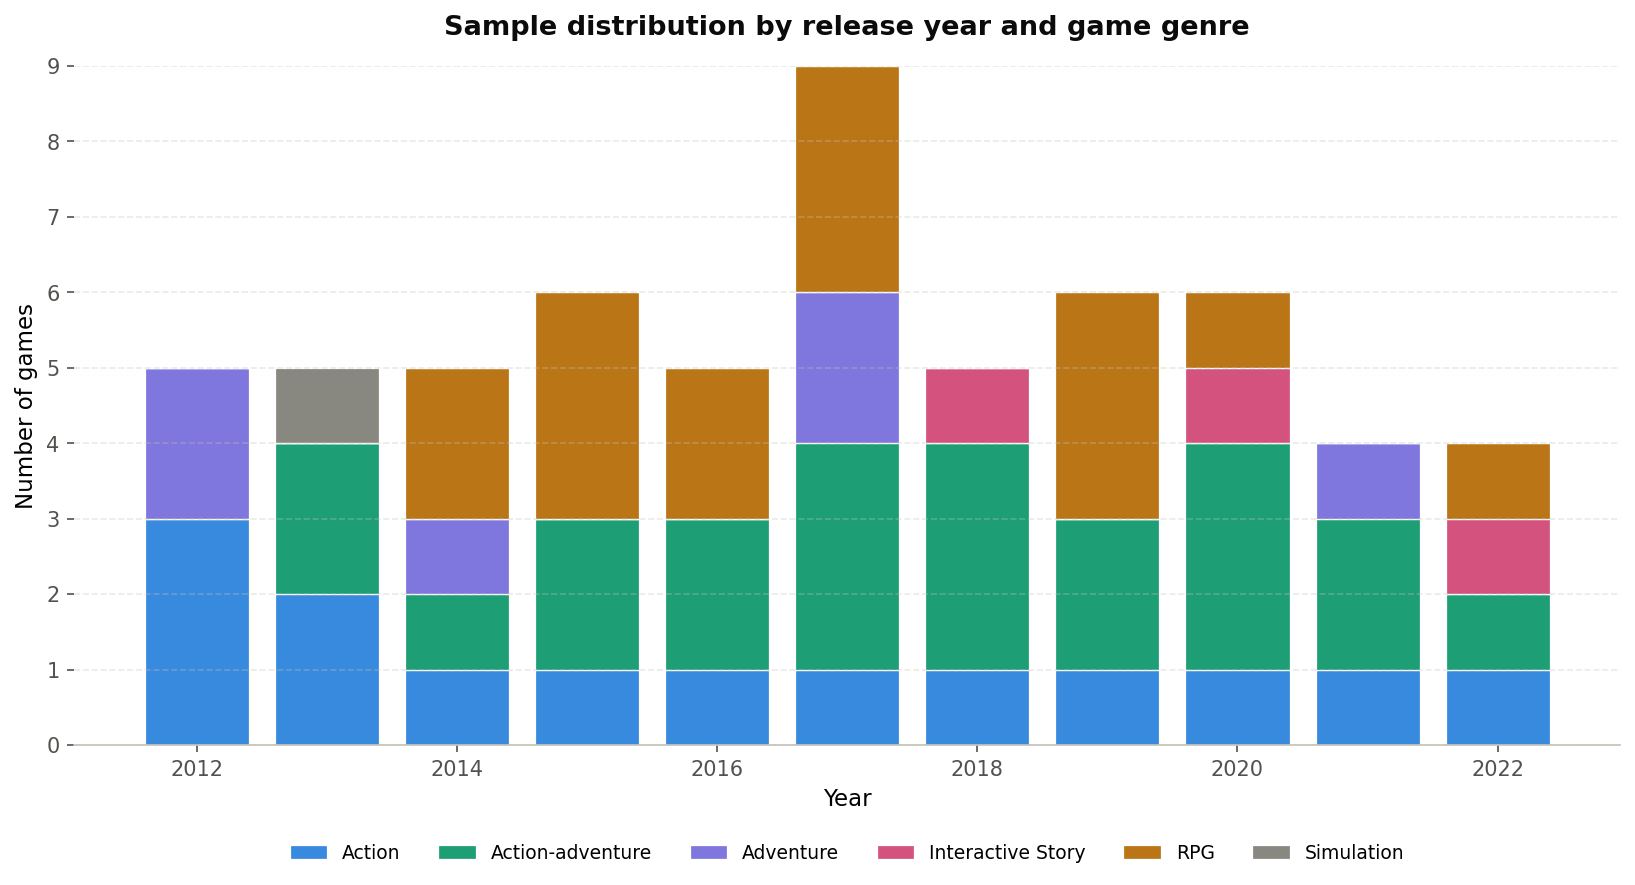

In [48]:
def chart_style(ax, pct_y=False):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.grid(axis="y", linestyle="--", alpha=0.35, color="#c3c2b7")
    ax.tick_params(axis="both", colors="#52514e", labelsize=10)
    if pct_y:
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
    plt.tight_layout()

GENRE_COLORS = {
    "Action": "#378ADD", "Action-adventure": "#1D9E75", "Adventure": "#7F77DD",
    "Interactive Story": "#D4537E", "RPG": "#BA7517", "Simulation": "#888780",
}

dist = (
    df_aaa.drop_duplicates(subset="Game_Id")
    .groupby(["year", "Genre"]).size()
    .reset_index(name="count")
    .pivot(index="year", columns="Genre", values="count")
    .fillna(0)
)
dist = dist[[g for g in GENRE_COLORS if g in dist.columns]]  # fixed order

fig, ax = plt.subplots(figsize=(11, 6), dpi=150)
bottom = np.zeros(len(dist))
for genre in dist.columns:
    ax.bar(dist.index.astype(int), dist[genre], bottom=bottom,
           color=GENRE_COLORS[genre], label=genre,
           edgecolor="white", linewidth=0.6)
    bottom += dist[genre].values

ax.set_title("Sample distribution by release year and game genre",
             fontsize=13, fontweight="bold", pad=15, color="#0b0b0b")
ax.legend(ncol=6, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
ax.set_ylabel("Number of games", fontsize=11)
ax.set_xlabel("Year", fontsize=11)
chart_style(ax)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sample_by_year_genre.png"), dpi=300, bbox_inches="tight")
plt.show()

## 8. Figures of the paper

The three figures included in the paper, in the paper's format (single IEEE column width, serif font).

In [49]:
PAPER_STYLE = {
    "font.family": "serif",
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300,
}
FEMALE, MALE, ALL = "#0077BB", "#CC3311", "#888888"

def grid_y(ax):
    ax.grid(axis="y", linestyle="--", alpha=0.4, color="#cccccc")
    ax.set_axisbelow(True)

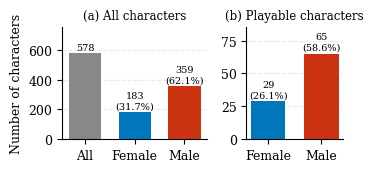

In [50]:
# Fig. 1 - Number of characters by gender: (a) all characters, (b) playable characters
with plt.rc_context(PAPER_STYLE):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(3.6, 1.8), gridspec_kw={"width_ratios": [3, 2]})

    n_all = len(characters)
    counts = characters["Gender"].value_counts()
    vals = [n_all, counts["Female"], counts["Male"]]
    bars = ax1.bar(["All", "Female", "Male"], vals, color=[ALL, FEMALE, MALE], width=0.65)
    for bar, v, show_pct in zip(bars, vals, [False, True, True]):
        label = f"{v}\n({v / n_all:.1%})" if show_pct else f"{v}"
        ax1.text(bar.get_x() + bar.get_width() / 2, v + 10, label, ha="center", va="bottom", fontsize=7)
    ax1.set_ylim(0, 750)
    ax1.set_ylabel("Number of characters")
    ax1.set_title("(a) All characters", fontsize=8.5)
    grid_y(ax1)

    play = characters[characters["Playable"] == 1]
    n_play = len(play)
    pcounts = play["Gender"].value_counts()
    pvals = [pcounts["Female"], pcounts["Male"]]
    pbars = ax2.bar(["Female", "Male"], pvals, color=[FEMALE, MALE], width=0.65)
    for bar, v in zip(pbars, pvals):
        ax2.text(bar.get_x() + bar.get_width() / 2, v + 1.5, f"{v}\n({v / n_play:.1%})", ha="center", va="bottom", fontsize=7)
    ax2.set_ylim(0, 85)
    ax2.set_title("(b) Playable characters", fontsize=8.5)
    grid_y(ax2)

    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "fig_character_counts.png"), bbox_inches="tight")
    plt.show()

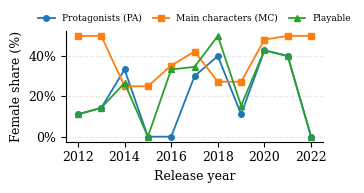

In [51]:
# Fig. 2 - Female share per release year, by narrative relevance criterion
with plt.rc_context(PAPER_STYLE):
    fig, ax = plt.subplots(figsize=(3.6, 2.0))
    for col, marker in zip(female_share_by_year.columns, ["o", "s", "^"]):
        ax.plot(female_share_by_year.index, female_share_by_year[col], marker=marker, markersize=4, linewidth=1.3, label=col)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100, decimals=0))
    ax.set_xlabel("Release year")
    ax.set_ylabel("Female share (%)")
    ax.set_xticks(range(2012, 2023, 2))
    ax.legend(ncol=3, frameon=False, fontsize=6.5, loc="lower center", bbox_to_anchor=(0.5, 1.0),
              handlelength=1.8, columnspacing=1.2)
    grid_y(ax)

    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "fig_share_by_role.png"), bbox_inches="tight")
    plt.show()

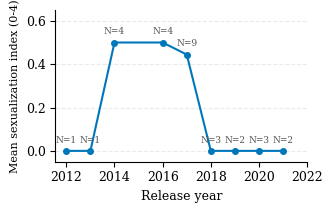

In [52]:
# Fig. 3 - Mean sexualization index of playable female characters per release year
with plt.rc_context(PAPER_STYLE):
    fig, ax = plt.subplots(figsize=(3.4, 2.2))
    ax.plot(h3_by_year.index, h3_by_year["Mean"], marker="o", markersize=4, linewidth=1.5, color=FEMALE)
    for year, row in h3_by_year.iterrows():
        ax.annotate(f"N={int(row['N'])}", (year, row["Mean"]), textcoords="offset points",
                    xytext=(0, 6), ha="center", fontsize=6.5, color="#555555")
    ax.set_xlabel("Release year")
    ax.set_ylabel("Mean sexualization index (0-4)", fontsize=8)
    ax.set_xticks(range(2012, 2023, 2))
    ax.set_ylim(-0.05, 0.65)
    grid_y(ax)

    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "fig_sexualization_year.png"), bbox_inches="tight")
    plt.show()